In [ ]:
import os
import sys
import numpy as np
import tensorflow as tf

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Working directory:", os.getcwd())

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow: 2.21.0
NumPy: 2.1.3
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Working directory: /content


In [ ]:
%pip install -q nibabel opencv-python-headless scikit-learn matplotlib pandas

In [ ]:
import nibabel as nib
import cv2
import sklearn
import matplotlib.pyplot as plt
import pandas as pd

print("All required packages imported successfully.")
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)

All required packages imported successfully.
OpenCV: 4.14.0
Scikit-learn: 1.6.1


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BrainAI_Project")

DATA_DIR = Path("/content/BraTS")
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"

for folder in [
    MODEL_DIR,
    CHECKPOINT_DIR,
    FIGURES_DIR,
    METRICS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created.")
print("Persistent project:", PROJECT_DIR)

Project folders created.
Persistent project: /content/drive/MyDrive/BrainAI_Project


In [ ]:
from pathlib import Path

possible_locations = [
    Path("/content/BraTS"),
    Path("/content/BraTS2021_Training_Data"),
    Path("/content/BraTS2021_Training_Data.zip"),
]

for path in possible_locations:
    print(f"{path}: {'FOUND' if path.exists() else 'not found'}")

/content/BraTS: not found
/content/BraTS2021_Training_Data: not found
/content/BraTS2021_Training_Data.zip: not found


In [ ]:
from pathlib import Path

zip_path = Path("/content/BraTS2021_Training_Data.zip")

if zip_path.exists():
    print("ZIP found!")
    print(f"Size: {zip_path.stat().st_size / (1024**2):.1f} MB")
else:
    print("ZIP not found. Check whether the upload finished.")

ZIP not found. Check whether the upload finished.


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/BraTS2021_Training_Data.zip")
extract_dir = Path("/content/BraTS")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

print("Extraction complete.")

Extraction complete.


In [ ]:
from pathlib import Path

patient_dirs = sorted(
    p for p in Path("/content/BraTS").rglob("BraTS2021_*")
    if p.is_dir()
    and (p / f"{p.name}_flair.nii.gz").exists()
)

print("Patients found:", len(patient_dirs))

if patient_dirs:
    print("Example patient:", patient_dirs[0])
    print("Files:")
    for file in sorted(patient_dirs[0].iterdir()):
        print(" -", file.name)

Patients found: 50
Example patient: /content/BraTS/BraTS2021_Training_Data/BraTS2021_01017
Files:
 - BraTS2021_01017_flair.nii.gz
 - BraTS2021_01017_seg.nii.gz
 - BraTS2021_01017_t1.nii.gz
 - BraTS2021_01017_t1ce.nii.gz
 - BraTS2021_01017_t2.nii.gz


In [ ]:
from pathlib import Path
import numpy as np
import nibabel as nib
import cv2
import tensorflow as tf
import json

PROJECT_DIR = Path("/content/drive/MyDrive/BrainAI_Project")
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [MODEL_DIR, CHECKPOINT_DIR, METRICS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path("/content/BraTS")

patient_dirs = sorted(
    p for p in DATA_ROOT.rglob("BraTS2021_*")
    if p.is_dir()
    and all(
        (p / f"{p.name}_{mod}.nii.gz").exists()
        for mod in ["flair", "t1", "t1ce", "t2", "seg"]
    )
)

print("Patients found:", len(patient_dirs))
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Project folder:", PROJECT_DIR)

assert len(patient_dirs) >= 5, (
    "Not enough patients found. Check the ZIP extraction path."
)

Patients found: 50
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project folder: /content/drive/MyDrive/BrainAI_Project


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42
MAX_PATIENTS = 20

selected_patients = patient_dirs[:MAX_PATIENTS]

train_patients, val_patients = train_test_split(
    selected_patients,
    test_size=0.2,
    random_state=SEED
)

print("Total selected:", len(selected_patients))
print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

print("\nValidation patient IDs:")
for p in val_patients:
    print(p.name)

Total selected: 20
Training patients: 16
Validation patients: 4

Validation patient IDs:
BraTS2021_01017
BraTS2021_01040
BraTS2021_01038
BraTS2021_01018


In [ ]:
IMG_SIZE = 128
MODALITIES = ["flair", "t1", "t1ce", "t2"]


def load_patient(patient_dir):
    patient_id = patient_dir.name
    channels = []

    for modality in MODALITIES:
        path = patient_dir / f"{patient_id}_{modality}.nii.gz"
        volume = nib.load(str(path)).get_fdata(dtype=np.float32)
        channels.append(volume)

    image = np.stack(channels, axis=-1)

    seg_path = patient_dir / f"{patient_id}_seg.nii.gz"
    mask = nib.load(str(seg_path)).get_fdata().astype(np.uint8)

    return image, mask


def normalize_image(image):
    output = np.zeros_like(image, dtype=np.float32)

    for channel in range(image.shape[-1]):
        x = image[..., channel]
        nonzero = x > 0

        if np.any(nonzero):
            values = x[nonzero]
            mean = values.mean()
            std = values.std()
            output_channel = output[..., channel]
            output_channel[nonzero] = (
                (values - mean) / max(float(std), 1e-6)
            )

    return output


def patient_to_slices(patient_dir):
    image, mask = load_patient(patient_dir)
    image = normalize_image(image)
    mask = (mask > 0).astype(np.uint8)

    xs, ys = [], []

    for z in range(image.shape[2]):
        image_slice = image[:, :, z, :]

        # Skip slices that contain neither useful MRI signal nor tumor.
        if not np.any(image_slice):
            continue

        mask_slice = mask[:, :, z]

        resized_x = cv2.resize(
            image_slice,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

        resized_y = cv2.resize(
            mask_slice,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        xs.append(resized_x)
        ys.append(resized_y[..., None].astype(np.float32))

    if not xs:
        raise ValueError(f"No usable slices in {patient_dir.name}")

    return np.asarray(xs, np.float32), np.asarray(ys, np.float32)


print("Preprocessing functions ready.")

Preprocessing functions ready.


In [ ]:
def build_split(patient_list, split_name):
    x_parts, y_parts = [], []

    for index, patient_dir in enumerate(patient_list, start=1):
        print(
            f"{split_name}: patient {index}/{len(patient_list)} "
            f"- {patient_dir.name}"
        )

        x_patient, y_patient = patient_to_slices(patient_dir)

        x_parts.append(x_patient)
        y_parts.append(y_patient)

    X = np.concatenate(x_parts, axis=0)
    Y = np.concatenate(y_parts, axis=0)

    return X, Y


X_train, Y_train = build_split(train_patients, "Train")
X_val, Y_val = build_split(val_patients, "Validation")

print("\nTraining arrays:", X_train.shape, Y_train.shape)
print("Validation arrays:", X_val.shape, Y_val.shape)

print("Training mask range:", Y_train.min(), Y_train.max())
print("Validation mask range:", Y_val.min(), Y_val.max())

np.savez_compressed(
    PROJECT_DIR / "prototype_data.npz",
    X_train=X_train,
    Y_train=Y_train,
    X_val=X_val,
    Y_val=Y_val
)

print("Preprocessed arrays saved to Google Drive.")

Train: patient 1/16 - BraTS2021_01025
Train: patient 2/16 - BraTS2021_01022
Train: patient 3/16 - BraTS2021_01033
Train: patient 4/16 - BraTS2021_01020
Train: patient 5/16 - BraTS2021_01041
Train: patient 6/16 - BraTS2021_01039
Train: patient 7/16 - BraTS2021_01035
Train: patient 8/16 - BraTS2021_01019
Train: patient 9/16 - BraTS2021_01026
Train: patient 10/16 - BraTS2021_01042
Train: patient 11/16 - BraTS2021_01021
Train: patient 12/16 - BraTS2021_01034
Train: patient 13/16 - BraTS2021_01024
Train: patient 14/16 - BraTS2021_01027
Train: patient 15/16 - BraTS2021_01037
Train: patient 16/16 - BraTS2021_01023
Validation: patient 1/4 - BraTS2021_01017
Validation: patient 2/4 - BraTS2021_01040
Validation: patient 3/4 - BraTS2021_01038
Validation: patient 4/4 - BraTS2021_01018

Training arrays: (2232, 128, 128, 4) (2232, 128, 128, 1)
Validation arrays: (554, 128, 128, 4) (554, 128, 128, 1)
Training mask range: 0.0 1.0
Validation mask range: 0.0 1.0
Preprocessed arrays saved to Google Drive.

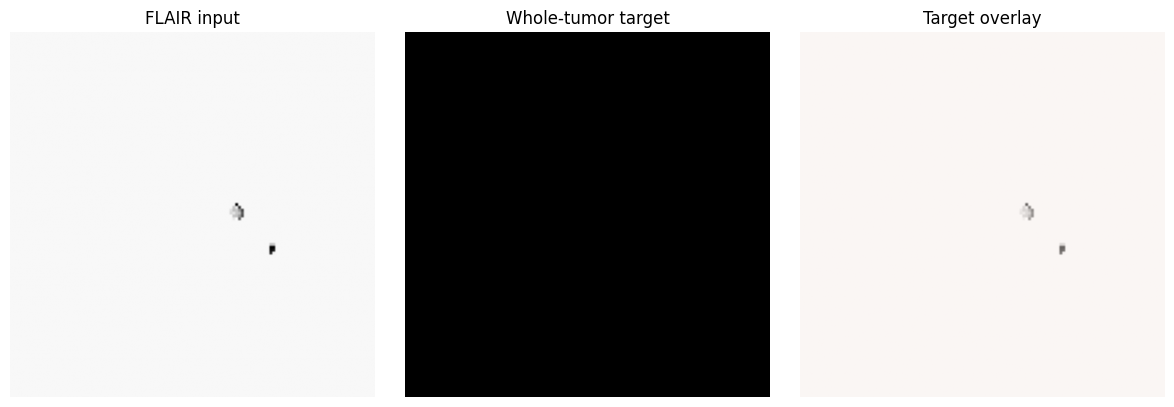

In [ ]:
import matplotlib.pyplot as plt

index = min(0, len(X_train) - 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(X_train[index, :, :, 0], cmap="gray")
axes[0].set_title("FLAIR input")

axes[1].imshow(Y_train[index, :, :, 0], cmap="gray")
axes[1].set_title("Whole-tumor target")

axes[2].imshow(X_train[index, :, :, 0], cmap="gray")
axes[2].imshow(
    Y_train[index, :, :, 0],
    cmap="Reds",
    alpha=0.4
)
axes[2].set_title("Target overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "preprocessing_preview.png", dpi=150)
plt.show()

Training slices: 2232
Slices containing tumor: 997
Selected slice: 85
Tumor pixels: 4
Mask values: [0. 1.]


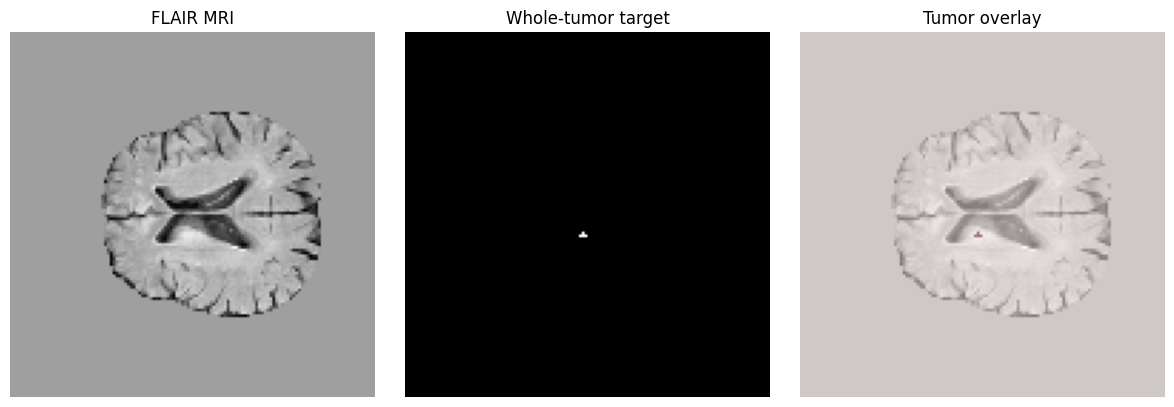

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Find a training slice that actually contains tumor
tumor_counts = Y_train.sum(axis=(1, 2, 3))
tumor_indices = np.where(tumor_counts > 0)[0]

print("Training slices:", len(Y_train))
print("Slices containing tumor:", len(tumor_indices))

if len(tumor_indices) > 0:
    i = tumor_indices[0]

    print("Selected slice:", i)
    print("Tumor pixels:", int(tumor_counts[i]))
    print("Mask values:", np.unique(Y_train[i]))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(X_train[i, :, :, 0], cmap="gray")
    axes[0].set_title("FLAIR MRI")

    axes[1].imshow(Y_train[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Whole-tumor target")

    axes[2].imshow(X_train[i, :, :, 0], cmap="gray")
    axes[2].imshow(
        Y_train[i, :, :, 0],
        cmap="Reds",
        alpha=0.5,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Tumor overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No tumor-positive slices found. We need to inspect the masks.")

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def build_unet(input_shape=(128, 128, 4)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    c1 = layers.Conv2D(32, 3, activation="relu", padding="same")(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(64, 3, activation="relu", padding="same")(p1)
    c2 = layers.Conv2D(64, 3, activation="relu", padding="same")(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(128, 3, activation="relu", padding="same")(p2)
    c3 = layers.Conv2D(128, 3, activation="relu", padding="same")(c3)

    # Decoder
    u4 = layers.UpSampling2D()(c3)
    u4 = layers.Concatenate()([u4, c2])
    c4 = layers.Conv2D(64, 3, activation="relu", padding="same")(u4)
    c4 = layers.Conv2D(64, 3, activation="relu", padding="same")(c4)

    u5 = layers.UpSampling2D()(c4)
    u5 = layers.Concatenate()([u5, c1])
    c5 = layers.Conv2D(32, 3, activation="relu", padding="same")(u5)
    c5 = layers.Conv2D(32, 3, activation="relu", padding="same")(c5)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c5)

    return Model(inputs, outputs, name="BrainTumorUNet")


model = build_unet()
model.summary()

Model: "BrainTumorUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,184 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_8[0][0]  

 Total params: 471,841 (1.80 MB)

 Trainable params: 471,841 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def dice_coef(y_true, y_pred):
    smooth = 1e-6
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[dice_coef]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger, EarlyStopping

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = MODEL_DIR / "brain_tumor_unet_best.keras"
checkpoint_path = CHECKPOINT_DIR / "brain_tumor_unet_latest.keras"
log_path = METRICS_DIR / "training_log.csv"

callbacks = [
    ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(checkpoint_path),
        save_best_only=False,
        save_freq="epoch",
        verbose=0
    ),
    CSVLogger(str(log_path), append=True),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

print("Checkpoint path:", checkpoint_path)
print("Best model path:", best_model_path)
print("Log path:", log_path)

Checkpoint path: /content/drive/MyDrive/BrainAI_Project/checkpoints/brain_tumor_unet_latest.keras
Best model path: /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras
Log path: /content/drive/MyDrive/BrainAI_Project/results/metrics/training_log.csv


In [ ]:
BATCH_SIZE = 8
EPOCHS = 10

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - dice_coef: 0.2630 - loss: 1.0005
Epoch 1: val_dice_coef improved from None to 0.40566, saving model to /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 34s 59ms/step - dice_coef: 0.5304 - loss: 0.5715 - val_dice_coef: 0.4057 - val_loss: 0.6012
Epoch 2/10
278/279 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - dice_coef: 0.8295 - loss: 0.1827
Epoch 2: val_dice_coef improved from 0.40566 to 0.42371, saving model to /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - dice_coef: 0.8466 - loss: 0.1647 - val_dice_coef: 0.4237 - val_loss: 0.5826
Epoch 3/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - dice_coef: 0.8485 

In [ ]:
print("Best model exists:", best_model_path.exists())
print("Latest checkpoint exists:", checkpoint_path.exists())
print("Training log exists:", log_path.exists())

if log_path.exists():
    import pandas as pd
    display(pd.read_csv(log_path).tail())

Best model exists: True
Latest checkpoint exists: True
Training log exists: True


,epoch,dice_coef,loss,val_dice_coef,val_loss
10,5,0.907563,0.098709,0.469820,0.533122
11,6,0.893663,0.114819,0.446553,0.561057
12,7,0.921534,0.084705,0.473564,0.528762
13,8,0.911715,0.093706,0.461031,0.545966
14,9,0.892506,0.114801,0.463967,0.542360


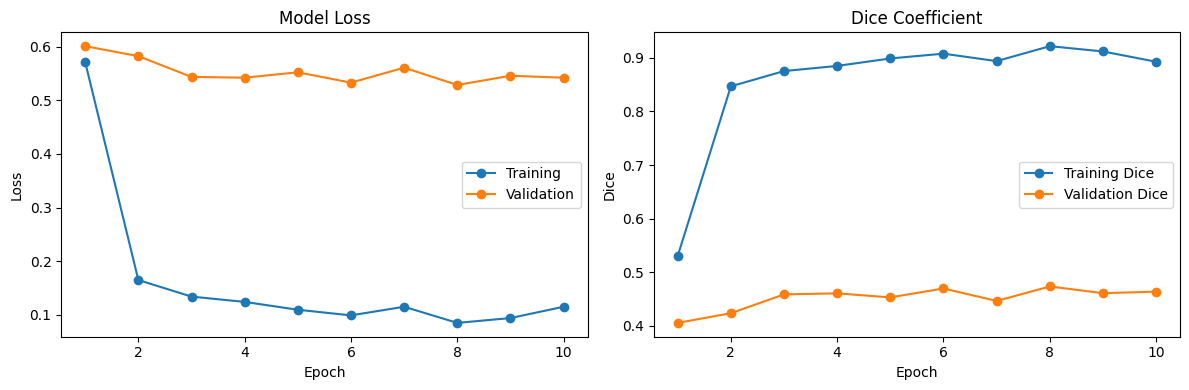

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

history_dict = history.history
epochs_ran = range(1, len(history_dict["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, history_dict["loss"], marker="o", label="Training")
axes[0].plot(epochs_ran, history_dict["val_loss"], marker="o", label="Validation")
axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    epochs_ran,
    history_dict["dice_coef"],
    marker="o",
    label="Training Dice"
)
axes[1].plot(
    epochs_ran,
    history_dict["val_dice_coef"],
    marker="o",
    label="Validation Dice"
)
axes[1].set_title("Dice Coefficient")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=160)
plt.show()

In [ ]:
best_model_path = MODEL_DIR / "brain_tumor_unet_best.keras"

assert best_model_path.exists(), (
    f"Model not found: {best_model_path}. "
    "Check whether training completed and saved a checkpoint."
)

best_model = tf.keras.models.load_model(
    best_model_path,
    compile=False
)

print("Best model loaded successfully.")
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

Best model loaded successfully.
Input shape: (None, 128, 128, 4)
Output shape: (None, 128, 128, 1)


In [ ]:
from sklearn.metrics import jaccard_score

pred_probs = best_model.predict(
    X_val,
    batch_size=8,
    verbose=1
)

pred_masks = (pred_probs >= 0.5).astype(np.uint8)
true_masks = (Y_val >= 0.5).astype(np.uint8)

slice_dice = []
slice_iou = []

for true_mask, pred_mask in zip(true_masks, pred_masks):
    y_true = true_mask.ravel()
    y_pred = pred_mask.ravel()

    intersection = np.sum(y_true * y_pred)
    denominator = np.sum(y_true) + np.sum(y_pred)

    dice = (
        2 * intersection / denominator
        if denominator > 0 else 1.0
    )

    iou = jaccard_score(
        y_true,
        y_pred,
        zero_division=0
    )

    slice_dice.append(dice)
    slice_iou.append(iou)

print(f"Mean slice Dice: {np.mean(slice_dice):.4f}")
print(f"Mean slice IoU:  {np.mean(slice_iou):.4f}")
print(f"Validation slices: {len(slice_dice)}")

70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step
Mean slice Dice: 0.8511
Mean slice IoU:  0.4122
Validation slices: 554


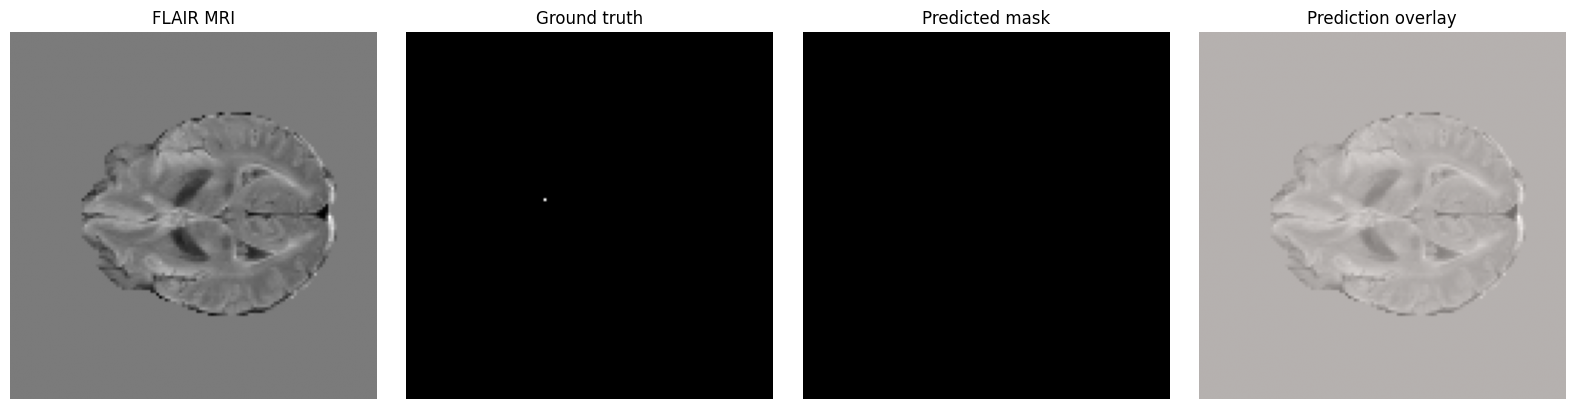

In [ ]:
import matplotlib.pyplot as plt

# Prefer a validation slice containing actual tumor.
tumor_slice_indices = np.where(
    Y_val.sum(axis=(1, 2, 3)) > 0
)[0]

if len(tumor_slice_indices) == 0:
    raise ValueError("No tumor-positive slices found in validation data.")

idx = int(tumor_slice_indices[0])

image_slice = X_val[idx, :, :, 0]
true_mask = Y_val[idx, :, :, 0]
prob_mask = pred_probs[idx, :, :, 0]
pred_mask = pred_masks[idx, :, :, 0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image_slice, cmap="gray")
axes[0].set_title("FLAIR MRI")

axes[1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground truth")

axes[2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Predicted mask")

axes[3].imshow(image_slice, cmap="gray")
axes[3].imshow(pred_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
axes[3].set_title("Prediction overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "prediction_preview.png", dpi=160)
plt.show()

In [ ]:
import pandas as pd

metrics = {
    "metric": ["mean_slice_dice", "mean_slice_iou"],
    "value": [float(np.mean(slice_dice)), float(np.mean(slice_iou))],
    "validation_slices": [len(slice_dice), len(slice_iou)],
    "threshold": [0.5, 0.5]
}

metrics_df = pd.DataFrame(metrics)

metrics_path = METRICS_DIR / "prototype_evaluation.csv"
metrics_df.to_csv(metrics_path, index=False)

display(metrics_df)
print("Saved:", metrics_path)

,metric,value,validation_slices,threshold
0,mean_slice_dice,0.851072,554,0.5
1,mean_slice_iou,0.412154,554,0.5


Saved: /content/drive/MyDrive/BrainAI_Project/results/metrics/prototype_evaluation.csv


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/BrainAI_Project")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

BEST_MODEL = MODEL_DIR / "brain_tumor_unet_best.keras"

assert BEST_MODEL.exists(), f"Saved model not found: {BEST_MODEL}"

print("Model:", BEST_MODEL)
print(f"Model size: {BEST_MODEL.stat().st_size / (1024**2):.2f} MB")
print("Model exists:", BEST_MODEL.exists())

for path in [
    METRICS_DIR / "prototype_evaluation.csv",
    METRICS_DIR / "training_log.csv",
    FIGURES_DIR / "training_curves.png",
    FIGURES_DIR / "prediction_preview.png",
]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path.name}")

metrics_file = METRICS_DIR / "prototype_evaluation.csv"

if metrics_file.exists():
    display(pd.read_csv(metrics_file))

Model: /content/drive/MyDrive/BrainAI_Project/models/brain_tumor_unet_best.keras
Model size: 5.48 MB
Model exists: True
FOUND: prototype_evaluation.csv
FOUND: training_log.csv
FOUND: training_curves.png
FOUND: prediction_preview.png


,metric,value,validation_slices,threshold
0,mean_slice_dice,0.851072,554,0.5
1,mean_slice_iou,0.412154,554,0.5


In [ ]:
import json

MODEL_CONFIG = {
    "project_name": "Brain AI Platform",
    "model_name": "BrainTumorUNet",
    "model_type": "2D U-Net",
    "task": "Binary whole-tumor segmentation",
    "dataset": "BraTS 2021",
    "input_size": [128, 128],
    "input_channels": 4,
    "modalities": ["flair", "t1", "t1ce", "t2"],
    "output_channels": 1,
    "prediction_threshold": 0.5,
    "mask_definition": "All nonzero BraTS segmentation labels are combined into one tumor class",
    "preprocessing": {
        "normalization": "Per-modality z-score normalization over nonzero voxels",
        "background_value": 0,
        "slice_axis": 2,
        "image_resize": "bilinear",
        "mask_resize": "nearest_neighbor"
    },
    "intended_use": "Research and educational demonstration only",
    "clinical_status": "Not validated for clinical diagnosis"
}

config_path = PROJECT_DIR / "model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(MODEL_CONFIG, f, indent=2)

print("Configuration saved:", config_path)
print(json.dumps(MODEL_CONFIG, indent=2))

Configuration saved: /content/drive/MyDrive/BrainAI_Project/model_config.json
{
  "project_name": "Brain AI Platform",
  "model_name": "BrainTumorUNet",
  "model_type": "2D U-Net",
  "task": "Binary whole-tumor segmentation",
  "dataset": "BraTS 2021",
  "input_size": [
    128,
    128
  ],
  "input_channels": 4,
  "modalities": [
    "flair",
    "t1",
    "t1ce",
    "t2"
  ],
  "output_channels": 1,
  "prediction_threshold": 0.5,
  "mask_definition": "All nonzero BraTS segmentation labels are combined into one tumor class",
  "preprocessing": {
    "normalization": "Per-modality z-score normalization over nonzero voxels",
    "background_value": 0,
    "slice_axis": 2,
    "image_resize": "bilinear",
    "mask_resize": "nearest_neighbor"
  },
  "intended_use": "Research and educational demonstration only",
  "clinical_status": "Not validated for clinical diagnosis"
}


In [ ]:
import shutil
import zipfile
from pathlib import Path

EXPORT_DIR = PROJECT_DIR / "deployment_export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Copy trained model and configuration.
shutil.copy2(
    BEST_MODEL,
    EXPORT_DIR / "brain_tumor_unet_best.keras"
)

shutil.copy2(
    config_path,
    EXPORT_DIR / "model_config.json"
)

# Copy evaluation and training artifacts if available.
artifact_paths = [
    METRICS_DIR / "prototype_evaluation.csv",
    METRICS_DIR / "training_log.csv",
    FIGURES_DIR / "training_curves.png",
    FIGURES_DIR / "prediction_preview.png",
]

for artifact in artifact_paths:
    if artifact.exists():
        shutil.copy2(artifact, EXPORT_DIR / artifact.name)

readme = """Brain AI Platform — Model Export

Model: 2D U-Net
Task: Binary whole-tumor segmentation
Input: Four aligned MRI modalities: FLAIR, T1, T1ce, T2
Input size: 128 x 128 pixels per slice
Output: Tumor probability mask per slice

Research prototype only. Not for clinical diagnosis.
Evaluation results are preliminary and depend on the limited
patient subset used during this experiment.

The inference pipeline must preserve modality order, alignment,
normalization, and slice orientation.
"""

(EXPORT_DIR / "README.txt").write_text(readme, encoding="utf-8")

ZIP_PATH = PROJECT_DIR / "BrainAI_Model_Export.zip"

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in EXPORT_DIR.iterdir():
        if file.is_file():
            archive.write(file, arcname=file.name)

print("Export folder:", EXPORT_DIR)
print("ZIP created:", ZIP_PATH)
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("Included files:")
for file in sorted(EXPORT_DIR.iterdir()):
    if file.is_file():
        print(f" - {file.name} ({file.stat().st_size / (1024**2):.2f} MB)")

Export folder: /content/drive/MyDrive/BrainAI_Project/deployment_export
ZIP created: /content/drive/MyDrive/BrainAI_Project/BrainAI_Model_Export.zip
ZIP size: 5.16 MB
Included files:
 - README.txt (0.00 MB)
 - brain_tumor_unet_best.keras (5.48 MB)
 - model_config.json (0.00 MB)
 - prediction_preview.png (0.05 MB)
 - prototype_evaluation.csv (0.00 MB)
 - training_curves.png (0.07 MB)
 - training_log.csv (0.00 MB)


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/BrainAI_Project/BrainAI_Model_Export.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q nibabel fastapi "uvicorn[standard]" python-multipart

In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/BrainAI_Project")
DEPLOY_DIR = PROJECT_DIR / "backend_export"
MODEL_DIR = DEPLOY_DIR / "model"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    PROJECT_DIR / "models" / "brain_tumor_unet_best.keras",
    MODEL_DIR / "brain_tumor_unet_best.keras"
)

shutil.copy2(
    PROJECT_DIR / "model_config.json",
    MODEL_DIR / "model_config.json"
)

print("Backend export folder:", DEPLOY_DIR)
print("Model and configuration copied successfully.")

Backend export folder: /content/drive/MyDrive/BrainAI_Project/backend_export
Model and configuration copied successfully.


In [ ]:
%%writefile /content/brain_ai_inference.py
from pathlib import Path
import json
import tempfile
import zipfile

import cv2
import nibabel as nib
import numpy as np
import tensorflow as tf

from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import FileResponse
from starlette.background import BackgroundTask

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "model" / "brain_tumor_unet_best.keras"
CONFIG_PATH = BASE_DIR / "model" / "model_config.json"

if not MODEL_PATH.exists():
    raise RuntimeError(f"Model file not found: {MODEL_PATH}")

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

IMG_SIZE = int(CONFIG["input_size"][0])
MODALITIES = ["flair", "t1", "t1ce", "t2"]
THRESHOLD = float(CONFIG["prediction_threshold"])

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

app = FastAPI(
    title="Brain AI Platform API",
    version="0.2.0",
    description=(
        "Research prototype for binary whole-tumor segmentation "
        "from four aligned BraTS-style MRI modalities."
    ),
)

app.add_middleware(
    CORSMiddleware,
        allow_origins=[
    "http://127.0.0.1:5500",
    "http://localhost:5500",
    "http://127.0.0.1:5501",
    "http://localhost:5501",
],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"],
)


def find_modality_files(root: Path):
    found = {}

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        lower = path.name.lower()

        if not (lower.endswith(".nii") or lower.endswith(".nii.gz")):
            continue

        for modality in MODALITIES:
            suffix = f"_{modality}.nii.gz"
            suffix_nii = f"_{modality}.nii"

            if lower.endswith(suffix) or lower.endswith(suffix_nii):
                if modality in found:
                    raise ValueError(
                        f"Multiple files found for modality {modality}."
                    )
                found[modality] = path

    missing = [m for m in MODALITIES if m not in found]
    if missing:
        raise ValueError(
            "ZIP must contain one NIfTI file for each modality. "
            f"Missing: {', '.join(missing)}"
        )

    return found


def load_and_validate_volumes(files_by_modality):
    images = {}
    reference_shape = None
    reference_affine = None

    for modality in MODALITIES:
        nii = nib.load(str(files_by_modality[modality]))
        volume = nii.get_fdata(dtype=np.float32)

        if volume.ndim != 3:
            raise ValueError(
                f"{modality} must be a 3D volume; received {volume.shape}."
            )

        if not np.isfinite(volume).all():
            raise ValueError(
                f"{modality} contains NaN or infinite values."
            )

        if reference_shape is None:
            reference_shape = volume.shape
            reference_affine = nii.affine
        else:
            if volume.shape != reference_shape:
                raise ValueError(
                    "MRI volumes have different array shapes. "
                    "Register and align them before uploading."
                )

            if not np.allclose(
                nii.affine, reference_affine, rtol=1e-4, atol=1e-3
            ):
                raise ValueError(
                    "MRI affine geometries differ. Align the modalities "
                    "before using this prototype."
                )

        images[modality] = volume

    return images, reference_shape, reference_affine


def normalize_volume(volume):
    result = np.zeros_like(volume, dtype=np.float32)
    nonzero = volume > 0

    if np.any(nonzero):
        values = volume[nonzero]
        mean = float(values.mean())
        std = max(float(values.std()), 1e-6)
        result[nonzero] = (values - mean) / std

    return result


def predict_volume(images):
    normalized = {
        modality: normalize_volume(images[modality])
        for modality in MODALITIES
    }

    reference = normalized["flair"]
    depth = reference.shape[2]

    output = np.zeros(reference.shape, dtype=np.uint8)
    probability_volume = np.zeros(reference.shape, dtype=np.float32)

    for z in range(depth):
        channels = [
            normalized[modality][:, :, z]
            for modality in MODALITIES
        ]

        resized_channels = [
            cv2.resize(
                channel,
                (IMG_SIZE, IMG_SIZE),
                interpolation=cv2.INTER_LINEAR,
            )
            for channel in channels
        ]

        model_input = np.stack(
            resized_channels, axis=-1
        ).astype(np.float32)[None, ...]

        probability = model.predict(
            model_input, verbose=0
        )[0, :, :, 0]

        original_slice = reference[:, :, z]

        probability = cv2.resize(
            probability,
            (original_slice.shape[1], original_slice.shape[0]),
            interpolation=cv2.INTER_LINEAR,
        )

        probability_volume[:, :, z] = probability
        output[:, :, z] = (probability >= THRESHOLD).astype(np.uint8)

    return output, probability_volume


def cleanup_directory(path: Path):
    import shutil
    shutil.rmtree(path, ignore_errors=True)


@app.get("/")
def root():
    return {
        "message": "Brain AI Platform API is running",
        "model_loaded": True,
        "task": "Binary whole-tumor segmentation",
        "research_only": True,
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": model is not None,
    }


@app.post("/analyze")
async def analyze_mri(file: UploadFile = File(...)):
    if not file.filename or not file.filename.lower().endswith(".zip"):
        raise HTTPException(
            status_code=400,
            detail="Upload a ZIP containing the four aligned MRI NIfTI files.",
        )

    temp_root = Path(tempfile.mkdtemp(prefix="brain_ai_"))

    try:
        zip_path = temp_root / "upload.zip"
        extract_dir = temp_root / "input"
        extract_dir.mkdir()

        # Stream upload to disk rather than reading the entire ZIP into RAM.
        with zip_path.open("wb") as destination:
            while True:
                chunk = await file.read(1024 * 1024)
                if not chunk:
                    break
                destination.write(chunk)

        await file.close()

        try:
            with zipfile.ZipFile(zip_path) as archive:
                # Reject path traversal and ZIP entries that are not files/directories.
                for info in archive.infolist():
                    target = (extract_dir / info.filename).resolve()
                    if (
                        target != extract_dir.resolve()
                        and extract_dir.resolve() not in target.parents
                    ):
                        raise HTTPException(
                            status_code=400,
                            detail="ZIP contains an unsafe path.",
                        )
                archive.extractall(extract_dir)
        except zipfile.BadZipFile:
            raise HTTPException(
                status_code=400, detail="The uploaded file is not a valid ZIP."
            )

        try:
            modality_files = find_modality_files(extract_dir)
            images, shape, affine = load_and_validate_volumes(
                modality_files
            )
        except ValueError as exc:
            raise HTTPException(status_code=422, detail=str(exc))

        mask, probabilities = predict_volume(images)

        output_dir = temp_root / "output"
        output_dir.mkdir()

        reference_nii = nib.load(str(modality_files["flair"]))

        mask_path = output_dir / "whole_tumor_mask.nii.gz"
        prob_path = output_dir / "tumor_probability.nii.gz"

        nib.save(
            nib.Nifti1Image(mask.astype(np.uint8), affine, reference_nii.header),
            str(mask_path),
        )
        nib.save(
            nib.Nifti1Image(
                probabilities.astype(np.float32),
                affine,
                reference_nii.header,
            ),
            str(prob_path),
        )

        tumor_voxels = int(mask.sum())

        # Save JSON metadata with the downloadable mask.
        metadata_path = output_dir / "analysis_metadata.json"
        metadata_path.write_text(
            json.dumps(
                {
                    "task": "binary_whole_tumor_segmentation",
                    "volume_shape": list(shape),
                    "tumor_voxels": tumor_voxels,
                    "threshold": THRESHOLD,
                    "modalities": MODALITIES,
                    "research_only": True,
                    "clinical_warning": (
                        "This output is experimental and is not a clinical "
                        "diagnosis or a validated medical measurement."
                    ),
                },
                indent=2,
            ),
            encoding="utf-8",
        )

        result_zip = temp_root / "analysis_results.zip"

        with zipfile.ZipFile(
            result_zip, "w", compression=zipfile.ZIP_DEFLATED
        ) as archive:
            archive.write(mask_path, arcname=mask_path.name)
            archive.write(prob_path, arcname=prob_path.name)
            archive.write(metadata_path, arcname=metadata_path.name)

        return FileResponse(
            path=result_zip,
            media_type="application/zip",
            filename="brain_ai_analysis_results.zip",
            background=BackgroundTask(cleanup_directory, temp_root),
        )

    except HTTPException:
        cleanup_directory(temp_root)
        raise
    except Exception as exc:
        cleanup_directory(temp_root)
        raise HTTPException(
            status_code=500,
            detail=f"Analysis failed: {type(exc).__name__}: {exc}",
        )

Overwriting /content/brain_ai_inference.py


In [ ]:
import os

print("Current API process:", api_process.pid if "api_process" in globals() else "Unknown")
print("Backend file:", BACKEND_FILE if "BACKEND_FILE" in globals() else "Not defined")
print("Inference file exists:", os.path.exists("/content/brain_ai_inference.py"))
print("Drive backend exists:", os.path.exists(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
))

Current API process: 12391
Backend file: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py
Inference file exists: True
Drive backend exists: True


In [ ]:
from pathlib import Path
import shutil

DEPLOY_DIR = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")
MODEL_DIR = DEPLOY_DIR / "model"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    "/content/brain_ai_inference.py",
    DEPLOY_DIR / "main.py"
)

print("Backend file saved:", DEPLOY_DIR / "main.py")
print("Model file exists:", (MODEL_DIR / "brain_tumor_unet_best.keras").exists())
print("Configuration exists:", (MODEL_DIR / "model_config.json").exists())

Backend file saved: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py
Model file exists: True
Configuration exists: True


In [ ]:
%%writefile /content/requirements_brain_ai.txt
fastapi
uvicorn[standard]
python-multipart
tensorflow
nibabel
numpy
opencv-python-headless

Writing /content/requirements_brain_ai.txt


In [ ]:
from pathlib import Path
import shutil

DEPLOY_DIR = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")

shutil.copy2(
    "/content/requirements_brain_ai.txt",
    DEPLOY_DIR / "requirements.txt"
)

print("Requirements saved:", DEPLOY_DIR / "requirements.txt")

Requirements saved: /content/drive/MyDrive/BrainAI_Project/backend_export/requirements.txt


In [ ]:
from pathlib import Path
import zipfile

DEPLOY_DIR = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")
BACKEND_ZIP = Path("/content/drive/MyDrive/BrainAI_Project/BrainAI_Backend.zip")

with zipfile.ZipFile(
    BACKEND_ZIP, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in DEPLOY_DIR.rglob("*"):
        if file.is_file():
            archive.write(file, arcname=file.relative_to(DEPLOY_DIR))

print("Backend ZIP:", BACKEND_ZIP)
print(f"Size: {BACKEND_ZIP.stat().st_size / (1024**2):.2f} MB")

Backend ZIP: /content/drive/MyDrive/BrainAI_Project/BrainAI_Backend.zip
Size: 5.06 MB


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/BrainAI_Project/BrainAI_Backend.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import zipfile

DATA_ROOT = Path("/content/BraTS")
TEST_ZIP = Path("/content/brain_ai_test_patient.zip")

if "val_patients" in globals() and len(val_patients) > 0:
    test_patient = Path(val_patients[0])
else:
    candidates = sorted(
        p for p in DATA_ROOT.rglob("BraTS2021_*")
        if p.is_dir()
        and all(
            (p / f"{p.name}_{m}.nii.gz").exists()
            for m in ["flair", "t1", "t1ce", "t2", "seg"]
        )
    )
    if not candidates:
        raise FileNotFoundError(
            "No complete BraTS patient folders found in /content/BraTS."
        )
    test_patient = candidates[0]
    print(
        "Note: validation patient list unavailable; using a dataset patient "
        "for an API smoke test, not an independent evaluation."
    )

with zipfile.ZipFile(TEST_ZIP, "w", zipfile.ZIP_DEFLATED) as archive:
    for modality in ["flair", "t1", "t1ce", "t2"]:
        path = test_patient / f"{test_patient.name}_{modality}.nii.gz"
        if not path.exists():
            raise FileNotFoundError(path)
        archive.write(path, arcname=path.name)

print("Test patient:", test_patient.name)
print("Test ZIP:", TEST_ZIP)
print(f"ZIP size: {TEST_ZIP.stat().st_size / (1024**2):.2f} MB")

Test patient: BraTS2021_01017
Test ZIP: /content/brain_ai_test_patient.zip
ZIP size: 8.82 MB


In [ ]:
import subprocess
import sys
import time
from pathlib import Path
import requests

DEPLOY_DIR = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")
LOG_FILE = Path("/content/brain_ai_api.log")

assert (DEPLOY_DIR / "main.py").exists()
assert (DEPLOY_DIR / "model" / "brain_tumor_unet_best.keras").exists()

log_handle = open(LOG_FILE, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "main:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(DEPLOY_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

# Wait up to 120 seconds for TensorFlow and the model to load.
api_ready = False

for _ in range(120):
    if api_process.poll() is not None:
        break
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health", timeout=2
        )
        if response.ok:
            api_ready = True
            print("API health response:", response.json())
            break
    except requests.RequestException:
        pass
    time.sleep(1)

if not api_ready:
    print("Backend did not become ready. Recent log output:")
    print(LOG_FILE.read_text(errors="replace")[-8000:])
    raise RuntimeError("Fix the backend startup error before continuing.")

API health response: {'status': 'healthy', 'model_loaded': True}


In [ ]:
import requests
from pathlib import Path

TEST_ZIP = Path("/content/brain_ai_test_patient.zip")
RESULT_ZIP = Path("/content/brain_ai_test_results.zip")

with TEST_ZIP.open("rb") as f:
    response = requests.post(
        "http://127.0.0.1:8000/analyze",
        files={
            "file": (
                TEST_ZIP.name,
                f,
                "application/zip",
            )
        },
        timeout=900,
    )

print("HTTP status:", response.status_code)
print("Response content type:", response.headers.get("content-type"))

if response.ok:
    RESULT_ZIP.write_bytes(response.content)
    print("Results saved:", RESULT_ZIP)
    print(f"Results size: {RESULT_ZIP.stat().st_size / (1024**2):.2f} MB")
else:
    print("Error response:", response.text[:5000])
    raise RuntimeError("Inference test failed. Inspect the error before proceeding.")

HTTP status: 500
Response content type: application/json
Error response: {"detail":"Analysis failed: TypeError: list indices must be integers or slices, not str"}


RuntimeError: Inference test failed. Inspect the error before proceeding.

In [ ]:
from pathlib import Path

backend_file = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

source = backend_file.read_text(encoding="utf-8")

start = source.index("def predict_volume(images):")
end = source.index("\ndef cleanup_directory", start)

fixed_function = '''def predict_volume(images):
    # Keep modalities keyed by name, matching the training order.
    normalized = {
        modality: normalize_volume(images[modality])
        for modality in MODALITIES
    }

    reference = normalized["flair"]
    depth = reference.shape[2]

    output = np.zeros(reference.shape, dtype=np.uint8)
    probability_volume = np.zeros(reference.shape, dtype=np.float32)

    for z in range(depth):
        channels = [
            normalized[modality][:, :, z]
            for modality in MODALITIES
        ]

        resized_channels = [
            cv2.resize(
                channel,
                (IMG_SIZE, IMG_SIZE),
                interpolation=cv2.INTER_LINEAR,
            )
            for channel in channels
        ]

        model_input = np.stack(
            resized_channels, axis=-1
        ).astype(np.float32)[None, ...]

        probability = model.predict(
            model_input, verbose=0
        )[0, :, :, 0]

        original_shape = reference[:, :, z].shape

        probability = cv2.resize(
            probability,
            (original_shape[1], original_shape[0]),
            interpolation=cv2.INTER_LINEAR,
        )

        probability_volume[:, :, z] = probability
        output[:, :, z] = (
            probability >= THRESHOLD
        ).astype(np.uint8)

    return output, probability_volume

'''

source = source[:start] + fixed_function + source[end:]
backend_file.write_text(source, encoding="utf-8")

print("Fixed preprocessing function saved.")
print("Backend file:", backend_file)

Fixed preprocessing function saved.
Backend file: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py


In [ ]:
import subprocess
import sys
import time
import requests
from pathlib import Path

# Stop the previous server.
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    try:
        api_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        api_process.kill()
        api_process.wait()

DEPLOY_DIR = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export"
)
LOG_FILE = Path("/content/brain_ai_api.log")

log_handle = open(LOG_FILE, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "main:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(DEPLOY_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

ready = False

for _ in range(120):
    if api_process.poll() is not None:
        break
    try:
        r = requests.get(
            "http://127.0.0.1:8000/health", timeout=2
        )
        if r.ok:
            print("API restarted:", r.json())
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(1)

if not ready:
    print(LOG_FILE.read_text(errors="replace")[-6000:])
    raise RuntimeError("API did not restart successfully.")

API restarted: {'status': 'healthy', 'model_loaded': True}


In [ ]:
import requests
from pathlib import Path

TEST_ZIP = Path("/content/brain_ai_test_patient.zip")
RESULT_ZIP = Path("/content/brain_ai_test_results.zip")

with TEST_ZIP.open("rb") as f:
    response = requests.post(
        "http://127.0.0.1:8000/analyze",
        files={
            "file": (
                TEST_ZIP.name,
                f,
                "application/zip",
            )
        },
        timeout=900,
    )

print("HTTP status:", response.status_code)
print("Content type:", response.headers.get("content-type"))

if response.ok:
    RESULT_ZIP.write_bytes(response.content)
    print("Inference succeeded.")
    print("Results saved:", RESULT_ZIP)
else:
    print(response.text[:5000])

HTTP status: 200
Content type: application/zip
Inference succeeded.
Results saved: /content/brain_ai_test_results.zip


In [ ]:
from pathlib import Path

backend_file = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

source = backend_file.read_text(encoding="utf-8")

# Add imports if they are not already present.
if "import base64" not in source:
    source = source.replace(
        "import json",
        "import json\nimport base64\nimport uuid"
    )

if "from fastapi.responses import FileResponse" in source:
    source = source.replace(
        "from fastapi.responses import FileResponse",
        "from fastapi.responses import FileResponse"
    )

# Replace the old endpoint and everything below it.
route_start = source.index('@app.post("/analyze")')

new_routes = r'''
RESULTS_ROOT = BASE_DIR / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)


def png_data_url(image):
    """Encode a uint8 grayscale or RGB image for browser display."""
    import cv2
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise RuntimeError("Could not encode preview image.")
    return "data:image/png;base64," + base64.b64encode(
        encoded.tobytes()
    ).decode("ascii")


@app.post("/analyze")
async def analyze_mri(file: UploadFile = File(...)):
    if not file.filename or not file.filename.lower().endswith(".zip"):
        raise HTTPException(
            status_code=400,
            detail="Upload a ZIP containing the four aligned MRI NIfTI files.",
        )

    temp_root = Path(tempfile.mkdtemp(prefix="brain_ai_"))

    try:
        zip_path = temp_root / "upload.zip"
        extract_dir = temp_root / "input"
        extract_dir.mkdir()

        with zip_path.open("wb") as destination:
            while True:
                chunk = await file.read(1024 * 1024)
                if not chunk:
                    break
                destination.write(chunk)

        await file.close()

        try:
            with zipfile.ZipFile(zip_path) as archive:
                for info in archive.infolist():
                    target = (extract_dir / info.filename).resolve()
                    if (
                        target != extract_dir.resolve()
                        and extract_dir.resolve() not in target.parents
                    ):
                        raise HTTPException(
                            status_code=400,
                            detail="ZIP contains an unsafe path.",
                        )
                archive.extractall(extract_dir)
        except zipfile.BadZipFile:
            raise HTTPException(
                status_code=400,
                detail="The uploaded file is not a valid ZIP.",
            )

        try:
            modality_files = find_modality_files(extract_dir)
            images, shape, affine = load_and_validate_volumes(
                modality_files
            )
        except ValueError as exc:
            raise HTTPException(status_code=422, detail=str(exc))

        mask, probabilities = predict_volume(images)

        # Pick a slice with the largest predicted region for the preview.
        slice_counts = mask.sum(axis=(0, 1))
        preview_slice = (
            int(np.argmax(slice_counts))
            if int(slice_counts.max()) > 0
            else int(mask.shape[2] // 2)
        )

        flair_slice = images["flair"][:, :, preview_slice]
        mask_slice = mask[:, :, preview_slice]

        # Scale the FLAIR slice for display only; inference is unchanged.
        nonzero = flair_slice[flair_slice > 0]
        if nonzero.size:
            low, high = np.percentile(nonzero, [1, 99])
        else:
            low, high = float(flair_slice.min()), float(flair_slice.max())

        if high <= low:
            high = low + 1.0

        flair_display = np.clip(
            (flair_slice - low) / (high - low) * 255,
            0, 255
        ).astype(np.uint8)

        # OpenCV expects width x height when resizing.
        display_size = (256, 256)
        flair_preview = cv2.resize(
            flair_display, display_size,
            interpolation=cv2.INTER_LINEAR
        )
        mask_preview = cv2.resize(
            mask_slice.astype(np.uint8) * 255,
            display_size,
            interpolation=cv2.INTER_NEAREST
        )

        overlay = cv2.cvtColor(flair_preview, cv2.COLOR_GRAY2RGB)
        overlay[mask_preview > 0] = (
            0.55 * overlay[mask_preview > 0]
            + 0.45 * np.array([255, 40, 40])
        ).astype(np.uint8)

        # Save the full-resolution volumes for download.
        result_id = uuid.uuid4().hex
        result_dir = RESULTS_ROOT / result_id
        result_dir.mkdir(parents=True, exist_ok=False)

        reference_nii = nib.load(str(modality_files["flair"]))

        mask_path = result_dir / "whole_tumor_mask.nii.gz"
        probability_path = result_dir / "tumor_probability.nii.gz"

        nib.save(
            nib.Nifti1Image(
                mask.astype(np.uint8),
                reference_nii.affine,
                reference_nii.header.copy(),
            ),
            str(mask_path),
        )
        nib.save(
            nib.Nifti1Image(
                probabilities.astype(np.float32),
                reference_nii.affine,
                reference_nii.header.copy(),
            ),
            str(probability_path),
        )

        tumor_voxels = int(mask.sum())

        metadata = {
            "result_id": result_id,
            "task": "Binary whole-tumor segmentation",
            "volume_shape": list(shape),
            "tumor_voxels": tumor_voxels,
            "preview_slice_index": preview_slice,
            "threshold": THRESHOLD,
            "modalities": MODALITIES,
            "research_only": True,
            "clinical_warning": (
                "Experimental research output; not a clinical diagnosis."
            ),
        }

        (result_dir / "analysis_metadata.json").write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8",
        )

        result_zip = result_dir / "analysis_results.zip"
        with zipfile.ZipFile(
            result_zip, "w", compression=zipfile.ZIP_DEFLATED
        ) as archive:
            archive.write(mask_path, arcname=mask_path.name)
            archive.write(probability_path, arcname=probability_path.name)
            archive.write(
                result_dir / "analysis_metadata.json",
                arcname="analysis_metadata.json",
            )

        return {
            "status": "success",
            "result": metadata,
            "previews": {
                "flair": png_data_url(flair_preview),
                "mask": png_data_url(mask_preview),
                "overlay": png_data_url(overlay),
            },
            "download_url": f"/results/{result_id}/download",
        }

    except HTTPException:
        raise
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Analysis failed: {type(exc).__name__}: {exc}",
        )
    finally:
        cleanup_directory(temp_root)


@app.get("/results/{result_id}/download")
def download_results(result_id: str):
    # Accept only UUID-like hexadecimal IDs, not arbitrary filesystem paths.
    if len(result_id) != 32 or any(
        char not in "0123456789abcdef" for char in result_id
    ):
        raise HTTPException(status_code=400, detail="Invalid result ID.")

    result_zip = RESULTS_ROOT / result_id / "analysis_results.zip"
    if not result_zip.is_file():
        raise HTTPException(status_code=404, detail="Results not found.")

    return FileResponse(
        path=result_zip,
        media_type="application/zip",
        filename="brain_ai_analysis_results.zip",
    )
'''

source = source[:route_start] + new_routes
backend_file.write_text(source, encoding="utf-8")

print("Updated API routes saved to:", backend_file)

Updated API routes saved to: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py


In [ ]:
import subprocess
import sys
import time
import requests
from pathlib import Path

if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    try:
        api_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        api_process.kill()
        api_process.wait()

DEPLOY_DIR = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export"
)
LOG_FILE = Path("/content/brain_ai_api.log")

log_handle = open(LOG_FILE, "w")
api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "main:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(DEPLOY_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

ready = False
for _ in range(120):
    if api_process.poll() is not None:
        break
    try:
        r = requests.get("http://127.0.0.1:8000/health", timeout=2)
        if r.ok:
            print("API ready:", r.json())
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(1)

if not ready:
    print(LOG_FILE.read_text(errors="replace")[-8000:])
    raise RuntimeError("API startup failed.")

API ready: {'status': 'healthy', 'model_loaded': True}


In [ ]:
import requests
from pathlib import Path

TEST_ZIP = Path("/content/brain_ai_test_patient.zip")

with TEST_ZIP.open("rb") as f:
    response = requests.post(
        "http://127.0.0.1:8000/analyze",
        files={"file": (TEST_ZIP.name, f, "application/zip")},
        timeout=900,
    )

print("HTTP status:", response.status_code)

if not response.ok:
    print(response.text[:5000])
    raise RuntimeError("The updated API test failed.")

data = response.json()

print("Status:", data["status"])
print("Result metadata:", data["result"])
print("Preview keys:", list(data["previews"].keys()))
print("Download URL:", data["download_url"])

assert data["status"] == "success"
assert all(
    data["previews"][key].startswith("data:image/png;base64,")
    for key in ["flair", "mask", "overlay"]
)

print("JSON response and all three previews verified.")

HTTP status: 200
Status: success
Result metadata: {'result_id': 'dd00883f36f04c43ab78aa5e7ba68a62', 'task': 'Binary whole-tumor segmentation', 'volume_shape': [240, 240, 155], 'tumor_voxels': 99703, 'preview_slice_index': 102, 'threshold': 0.5, 'modalities': ['flair', 't1', 't1ce', 't2'], 'research_only': True, 'clinical_warning': 'Experimental research output; not a clinical diagnosis.'}
Preview keys: ['flair', 'mask', 'overlay']
Download URL: /results/dd00883f36f04c43ab78aa5e7ba68a62/download
JSON response and all three previews verified.



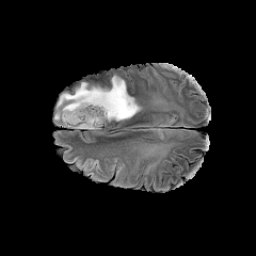
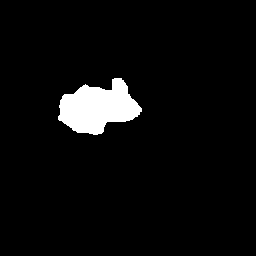
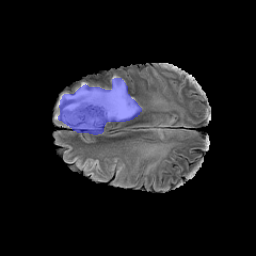

In [ ]:
from IPython.display import display, HTML
import base64

previews = data["previews"]

display(HTML(f"""
<div style="display:flex;gap:12px;flex-wrap:wrap;">
  <div>
    <p><b>FLAIR MRI</b></p>
    <img src="{previews['flair']}" width="256">
  </div>
  <div>
    <p><b>Predicted mask</b></p>
    <img src="{previews['mask']}" width="256">
  </div>
  <div>
    <p><b>Overlay</b></p>
    <img src="{previews['overlay']}" width="256">
  </div>
</div>
<p>Predicted tumor voxels: {data['result']['tumor_voxels']}</p>
<p>Preview slice: {data['result']['preview_slice_index']}</p>
<p><i>Research prototype only — not for clinical diagnosis.</i></p>
"""))

In [ ]:
from pathlib import Path

BACKEND_DIR = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export"
)

print("Backend directory exists:", BACKEND_DIR.exists())
print("\nFiles:")

for path in sorted(BACKEND_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(BACKEND_DIR))

Backend directory exists: True

Files:
__pycache__/main.cpython-313.pyc
main.py
model/brain_tumor_unet_best.keras
model/model_config.json
requirements.txt
results/dd00883f36f04c43ab78aa5e7ba68a62/analysis_metadata.json
results/dd00883f36f04c43ab78aa5e7ba68a62/analysis_results.zip
results/dd00883f36f04c43ab78aa5e7ba68a62/tumor_probability.nii.gz
results/dd00883f36f04c43ab78aa5e7ba68a62/whole_tumor_mask.nii.gz


In [ ]:
main_file = BACKEND_DIR / "main.py"
source = main_file.read_text(encoding="utf-8")

checks = {
    "JSON analysis response": '"previews"' in source,
    "Result download endpoint": "/results/{result_id}/download" in source,
    "CORS configuration": "CORSMiddleware" in source,
    "Analysis endpoint": "/analyze" in source,
}

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'} {label}")

✅ JSON analysis response
✅ Result download endpoint
❌ CORS configuration
✅ Analysis endpoint


In [ ]:

from pathlib import Path

BACKEND_FILE = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

print(BACKEND_FILE.exists())
print(BACKEND_FILE.read_text(encoding="utf-8")[:5000])


True
from pathlib import Path
import json
import base64
import uuid
import tempfile
import zipfile

import cv2
import nibabel as nib
import numpy as np
import tensorflow as tf

from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.responses import FileResponse
from starlette.background import BackgroundTask

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "model" / "brain_tumor_unet_best.keras"
CONFIG_PATH = BASE_DIR / "model" / "model_config.json"

if not MODEL_PATH.exists():
    raise RuntimeError(f"Model file not found: {MODEL_PATH}")

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

IMG_SIZE = int(CONFIG["input_size"][0])
MODALITIES = ["flair", "t1", "t1ce", "t2"]
THRESHOLD = float(CONFIG["prediction_threshold"])

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

app = FastAPI(
    title="Brain AI Platform API",
    version="0.2.0",
    description=(
        "Research prototype for binary whole-tumor 

In [ ]:

import subprocess
import sys

print(subprocess.run(
    ["ps", "-p", "12391", "-o", "pid=,args="],
    capture_output=True,
    text=True
).stdout)

print("\n--- Drive backend routes ---")
source = BACKEND_FILE.read_text(encoding="utf-8")

for term in [
    "CORSMiddleware",
    "def predict_volume",
    '@app.post("/analyze")',
    "/results/{result_id}/download",
]:
    print(f"{term}: {term in source}")


  12391 /usr/bin/python3 -m uvicorn main:app --host 127.0.0.1 --port 8000


--- Drive backend routes ---
CORSMiddleware: False
def predict_volume: True
@app.post("/analyze"): True
/results/{result_id}/download: True


In [ ]:

from pathlib import Path

BACKEND_FILE = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

source = BACKEND_FILE.read_text(encoding="utf-8")

print("--- First 100 lines ---")
for number, line in enumerate(source.splitlines()[:100], start=1):
    print(f"{number:03}: {line}")

print("\n--- Route and prediction function locations ---")
for number, line in enumerate(source.splitlines(), start=1):
    if (
        "def predict_volume" in line
        or '@app.post("/analyze")' in line
        or '@app.get("/health")' in line
        or "/results/{result_id}/download" in line
        or "CORSMiddleware" in line
    ):
        print(f"{number:03}: {line}")


--- First 100 lines ---
001: from pathlib import Path
002: import json
003: import base64
004: import uuid
005: import tempfile
006: import zipfile
007: 
008: import cv2
009: import nibabel as nib
010: import numpy as np
011: import tensorflow as tf
012: 
013: from fastapi import FastAPI, File, HTTPException, UploadFile
014: from fastapi.responses import FileResponse
015: from starlette.background import BackgroundTask
016: 
017: BASE_DIR = Path(__file__).resolve().parent
018: MODEL_PATH = BASE_DIR / "model" / "brain_tumor_unet_best.keras"
019: CONFIG_PATH = BASE_DIR / "model" / "model_config.json"
020: 
021: if not MODEL_PATH.exists():
022:     raise RuntimeError(f"Model file not found: {MODEL_PATH}")
023: 
024: with open(CONFIG_PATH, "r", encoding="utf-8") as f:
025:     CONFIG = json.load(f)
026: 
027: IMG_SIZE = int(CONFIG["input_size"][0])
028: MODALITIES = ["flair", "t1", "t1ce", "t2"]
029: THRESHOLD = float(CONFIG["prediction_threshold"])
030: 
031: model = tf.keras.models.load_

In [ ]:

source = BACKEND_FILE.read_text(encoding="utf-8")
lines = source.splitlines()

print("--- Prediction function ---")
for start, end in [(120, 198), (198, 245), (370, 420)]:
    print(f"\n--- Lines {start + 1}–{min(end, len(lines))} ---")
    for i in range(start, min(end, len(lines))):
        print(f"{i + 1:03}: {lines[i]}")


--- Prediction function ---

--- Lines 121–198 ---
121: 
122:     if np.any(nonzero):
123:         values = volume[nonzero]
124:         mean = float(values.mean())
125:         std = max(float(values.std()), 1e-6)
126:         result[nonzero] = (values - mean) / std
127: 
128:     return result
129: 
130: 
131: def predict_volume(images):
132:     # Keep modalities keyed by name, matching the training order.
133:     normalized = {
134:         modality: normalize_volume(images[modality])
135:         for modality in MODALITIES
136:     }
137: 
138:     reference = normalized["flair"]
139:     depth = reference.shape[2]
140: 
141:     output = np.zeros(reference.shape, dtype=np.uint8)
142:     probability_volume = np.zeros(reference.shape, dtype=np.float32)
143: 
144:     for z in range(depth):
145:         channels = [
146:             normalized[modality][:, :, z]
147:             for modality in MODALITIES
148:         ]
149: 
150:         resized_channels = [
151:             cv2.

In [ ]:

from pathlib import Path

BACKEND_FILE = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

source = BACKEND_FILE.read_text(encoding="utf-8")

if "from fastapi.middleware.cors import CORSMiddleware" not in source:
    source = source.replace(
        "from fastapi import FastAPI, File, HTTPException, UploadFile",
        "from fastapi import FastAPI, File, HTTPException, UploadFile\n"
        "from fastapi.middleware.cors import CORSMiddleware"
    )

if "app.add_middleware(CORSMiddleware" not in source:
    marker = '''app = FastAPI(
    title="Brain AI Platform API",
    version="0.2.0",
    description=(
        "Research prototype for binary whole-tumor segmentation "
        "from four aligned BraTS-style MRI modalities."
    ),
)
'''
    middleware = marker + '''
app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://127.0.0.1:5500",
        "http://localhost:5500",
        "http://127.0.0.1:5501",
        "http://localhost:5501",
    ],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"],
)
'''
    if marker not in source:
        raise RuntimeError(
            "Could not find the expected FastAPI app definition. "
            "No changes were saved."
        )
    source = source.replace(marker, middleware, 1)

BACKEND_FILE.write_text(source, encoding="utf-8")

# Verify the saved file
saved = BACKEND_FILE.read_text(encoding="utf-8")
print("CORS import:", "from fastapi.middleware.cors import CORSMiddleware" in saved)
print("CORS middleware:", "app.add_middleware(CORSMiddleware" in saved)
print("JSON analysis route:", '@app.post("/analyze")' in saved)
print("Download route:", '@app.get("/results/{result_id}/download")' in saved)
print("Saved to:", BACKEND_FILE)


CORS import: True
CORS middleware: False
JSON analysis route: True
Download route: True
Saved to: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py


In [ ]:

source = BACKEND_FILE.read_text(encoding="utf-8")

if "app.add_middleware(CORSMiddleware" not in source:
    marker = "\n\ndef find_modality_files(root: Path):"

    if marker not in source:
        raise RuntimeError(
            "Could not locate the insertion point. "
            "No additional changes were saved."
        )

    cors_block = '''

app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://127.0.0.1:5500",
        "http://localhost:5500",
        "http://127.0.0.1:5501",
        "http://localhost:5501",
    ],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"],
)
'''

    source = source.replace(marker, cors_block + marker, 1)
    BACKEND_FILE.write_text(source, encoding="utf-8")

saved = BACKEND_FILE.read_text(encoding="utf-8")
print("CORS import:", "from fastapi.middleware.cors import CORSMiddleware" in saved)
print("CORS middleware:", "app.add_middleware(CORSMiddleware" in saved)
print("Insertion location:")
lines = saved.splitlines()
for i, line in enumerate(lines):
    if "app.add_middleware(CORSMiddleware" in line:
        for j in range(max(0, i - 2), min(len(lines), i + 13)):
            print(f"{j + 1:03}: {lines[j]}")
        break


CORS import: True
CORS middleware: False
Insertion location:


In [ ]:

source = BACKEND_FILE.read_text(encoding="utf-8")
lines = source.splitlines()

for i, line in enumerate(lines):
    if "app = FastAPI(" in line:
        print("--- FastAPI definition and following lines ---")
        for j in range(i, min(i + 25, len(lines))):
            print(f"{j + 1:03}: {lines[j]}")
        break
else:
    print("Could not find 'app = FastAPI('")


--- FastAPI definition and following lines ---
034: app = FastAPI(
035:     title="Brain AI Platform API",
036:     version="0.2.0",
037:     description=(
038:         "Research prototype for binary whole-tumor segmentation "
039:         "from four aligned BraTS-style MRI modalities."
040:     ),
041: )
042: 
043: app.add_middleware(
044:     CORSMiddleware,
045:     allow_origins=[
046:         "http://127.0.0.1:5500",
047:         "http://localhost:5500",
048:         "http://127.0.0.1:5501",
049:         "http://localhost:5501",
050:     ],
051:     allow_credentials=False,
052:     allow_methods=["*"],
053:     allow_headers=["*"],
054: )
055: 
056: 
057: app.add_middleware(
058:     CORSMiddleware,


In [ ]:

from pathlib import Path

BACKEND_FILE = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

source = BACKEND_FILE.read_text(encoding="utf-8")

start = source.find("app = FastAPI(")
end = source.find("def find_modality_files(root: Path):")

if start == -1 or end == -1 or end <= start:
    raise RuntimeError(
        "Could not safely locate the FastAPI configuration. "
        "The file was not changed."
    )

clean_section = '''app = FastAPI(
    title="Brain AI Platform API",
    version="0.2.0",
    description=(
        "Research prototype for binary whole-tumor segmentation "
        "from four aligned BraTS-style MRI modalities."
    ),
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://127.0.0.1:5500",
        "http://localhost:5500",
        "http://127.0.0.1:5501",
        "http://localhost:5501",
    ],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"],
)


'''

source = source[:start] + clean_section + source[end:]
BACKEND_FILE.write_text(source, encoding="utf-8")

# Verify the saved configuration
saved = BACKEND_FILE.read_text(encoding="utf-8")
print("CORS import present:",
      "from fastapi.middleware.cors import CORSMiddleware" in saved)
print("CORS middleware blocks:",
      saved.count("app.add_middleware("))
print("Plain localhost URL present:",
      '"http://localhost:5500"' in saved)
print("Wildcard methods valid:",
      'allow_methods=["*"]' in saved)

compile(saved, str(BACKEND_FILE), "exec")
print("Python syntax check: PASSED")


CORS import present: True
CORS middleware blocks: 1
Plain localhost URL present: True
Wildcard methods valid: True
Python syntax check: PASSED


In [ ]:

import os
import signal
import subprocess
import sys
import time
from pathlib import Path

DEPLOY_DIR = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export"
)

# Stop the existing API process.
try:
    os.kill(12391, signal.SIGTERM)
    print("Sent stop signal to old API process.")
except ProcessLookupError:
    print("Old API process is already stopped.")

time.sleep(2)

# Start the API from the correct backend directory.
log_path = "/content/brain_ai_api.log"
log_handle = open(log_path, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "main:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(DEPLOY_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

time.sleep(5)

print("New API process ID:", api_process.pid)

# Check whether the server started successfully.
import urllib.request

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8000/health", timeout=5
    ) as response:
        print("Health endpoint:", response.status)
        print(response.read().decode("utf-8"))
except Exception as exc:
    print("Health check failed:", exc)
    print("\n--- API log ---")
    print(Path(log_path).read_text(encoding="utf-8")[-5000:])


Sent stop signal to old API process.
New API process ID: 23772
Health check failed: <urlopen error [Errno 111] Connection refused>

--- API log ---



In [ ]:

from pathlib import Path
import subprocess

print("--- API startup log ---")
log = Path("/content/brain_ai_api.log")
print(log.read_text(encoding="utf-8")[-8000:] if log.exists() else "Log not found")

print("\n--- Is the new process still running? ---")
print(subprocess.run(
    ["ps", "-p", "23772", "-o", "pid=,stat=,args="],
    capture_output=True,
    text=True
).stdout or "Process 23772 is not running.")


--- API startup log ---
W0000 00:00:1791736086.563398   23772 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [23772]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


--- Is the new process still running? ---
  23772 Sl   /usr/bin/python3 -m uvicorn main:app --host 127.0.0.1 --port 8000



In [ ]:

import urllib.request
import json

for endpoint in ["/health", "/"]:
    url = f"http://127.0.0.1:8000{endpoint}"
    try:
        with urllib.request.urlopen(url, timeout=15) as response:
            print(f"\n{endpoint} — HTTP {response.status}")
            print(response.read().decode("utf-8"))
    except Exception as exc:
        print(f"\n{endpoint} — FAILED: {exc}")



/health — HTTP 200
{"status":"healthy","model_loaded":true}

/ — HTTP 200
{"message":"Brain AI Platform API is running","model_loaded":true,"task":"Binary whole-tumor segmentation","research_only":true}


In [ ]:
from google.colab.output import eval_js

API_BASE_URL = eval_js("google.colab.kernel.proxyPort(8000)")
print("Your Colab API URL:")
print(API_BASE_URL)

Your Colab API URL:
https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:

import urllib.request
import json

health_url = API_BASE_URL.rstrip("/") + "/health"

try:
    with urllib.request.urlopen(health_url, timeout=20) as response:
        print("HTTP status:", response.status)
        print(response.read().decode("utf-8"))
except Exception as exc:
    print("Proxy test failed:", exc)


Proxy test failed: HTTP Error 404: Not Found


In [ ]:

print("Proxy URL returned by Colab:")
print(repr(API_BASE_URL))

print("\nHealth URL being tested:")
print(API_BASE_URL.rstrip("/") + "/health")

print("\nDirect API check inside Colab:")
import urllib.request

with urllib.request.urlopen(
    "http://127.0.0.1:8000/health", timeout=10
) as response:
    print("HTTP status:", response.status)
    print(response.read().decode("utf-8"))


Proxy URL returned by Colab:
'https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev'

Health URL being tested:
https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev/health

Direct API check inside Colab:
HTTP status: 200
{"status":"healthy","model_loaded":true}


In [ ]:

import re
from urllib.parse import urlparse
import urllib.request

raw_url = str(API_BASE_URL).strip()

# Convert Markdown link format [label](https://...) to a plain URL.
match = re.fullmatch(r"\[([^\]]+)\]\((https?://[^)]+)\)", raw_url)
if match:
    API_BASE_URL = match.group(2)
else:
    API_BASE_URL = raw_url

API_BASE_URL = API_BASE_URL.rstrip("/")

print("Clean API URL:", API_BASE_URL)
print("URL scheme:", urlparse(API_BASE_URL).scheme)

with urllib.request.urlopen(
    API_BASE_URL + "/health", timeout=20
) as response:
    print("HTTP status:", response.status)
    print(response.read().decode("utf-8"))


Clean API URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev
URL scheme: https


HTTPError: HTTP Error 404: Not Found

In [ ]:

from google.colab.output import eval_js
from urllib.parse import urlparse
import urllib.request
import re

raw = str(eval_js("google.colab.kernel.proxyPort(8000)")).strip()
print("Raw return:", repr(raw))

# Extract the actual HTTPS URL, even if the result contains Markdown.
match = re.search(r"https://[^\s)\]]+", raw)

if not match:
    raise RuntimeError("No HTTPS URL could be extracted from the proxy result.")

API_BASE_URL = match.group(0).rstrip("/")
print("Extracted URL:", API_BASE_URL)

response = urllib.request.urlopen(
    API_BASE_URL + "/health", timeout=20
)
print("HTTP status:", response.status)
print(response.read().decode("utf-8"))


Raw return: 'https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev'
Extracted URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


HTTPError: HTTP Error 404: Not Found

In [ ]:

import os
import signal
import subprocess
import sys
import time
from pathlib import Path

DEPLOY_DIR = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export"
)

# Stop the currently running server.
try:
    os.kill(23772, signal.SIGTERM)
    time.sleep(2)
except ProcessLookupError:
    pass

# Start the same backend, now accessible through Colab's port proxy.
log_handle = open("/content/brain_ai_api.log", "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "main:app",
        "--host", "0.0.0.0",
        "--port", "8000",
    ],
    cwd=str(DEPLOY_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

time.sleep(5)

print("New process ID:", api_process.pid)
print(Path("/content/brain_ai_api.log").read_text()[-2500:])

import urllib.request
with urllib.request.urlopen(
    "http://127.0.0.1:8000/health", timeout=15
) as response:
    print("Direct health check:", response.status)
    print(response.read().decode())


New process ID: 25820



URLError: <urlopen error [Errno 111] Connection refused>

In [ ]:

from google.colab.output import eval_js
import urllib.request

raw = str(eval_js("google.colab.kernel.proxyPort(8000)")).strip()

# Colab may format the URL as [label](URL).
if "](" in raw and raw.endswith(")"):
    proxy_url = raw.split("](", 1)[1][:-1]
else:
    proxy_url = raw

proxy_url = proxy_url.strip().rstrip("/")
print("Proxy URL:", proxy_url)

with urllib.request.urlopen(
    proxy_url + "/health", timeout=20
) as response:
    print("Proxy health status:", response.status)
    print(response.read().decode())


Proxy URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


HTTPError: HTTP Error 404: Not Found

In [ ]:

from pathlib import Path
import subprocess

print("--- API startup log ---")
log_path = Path("/content/brain_ai_api.log")
print(log_path.read_text(encoding="utf-8")[-6000:] if log_path.exists() else "Log not found")

print("\n--- Server process ---")
result = subprocess.run(
    ["ps", "-p", "25820", "-o", "pid=,stat=,args="],
    capture_output=True,
    text=True,
)
print(result.stdout or "Process 25820 is no longer running.")

print("\n--- Direct health check ---")
import urllib.request

try:
    with urllib.request.urlopen("http://127.0.0.1:8000/health", timeout=5) as r:
        print("HTTP", r.status, r.read().decode())
except Exception as e:
    print(type(e).__name__, str(e))


--- API startup log ---
W0000 00:00:1791736563.312139   25820 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [25820]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


--- Server process ---
  25820 Sl   /usr/bin/python3 -m uvicorn main:app --host 0.0.0.0 --port 8000


--- Direct health check ---
HTTP 200 {"status":"healthy","model_loaded":true}


In [ ]:

import re
from google.colab.output import eval_js
from urllib.parse import urlparse

raw = str(eval_js("google.colab.kernel.proxyPort(8000)")).strip()
print("Raw value:", repr(raw))

# If Colab returns Markdown, extract the URL inside parentheses.
match = re.search(r"\]\((https?://[^)]+)\)", raw)

if match:
    proxy_url = match.group(1)
else:
    # Otherwise extract a plain HTTPS URL.
    match = re.search(r"https://[^\s)\]]+", raw)
    if not match:
        raise RuntimeError("Could not extract a URL from the proxy result.")
    proxy_url = match.group(0)

proxy_url = proxy_url.rstrip("/")
print("Extracted value:", repr(proxy_url))
print("Scheme:", urlparse(proxy_url).scheme)
print("Host:", urlparse(proxy_url).netloc)
print("Health URL:", proxy_url + "/health")


Raw value: 'https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev'
Extracted value: 'https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev'
Scheme: https
Host: 8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev
Health URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev/health


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/BrainAI_Project")

print("Project folders:")
for path in root.iterdir():
    print(path.name, "—", "folder" if path.is_dir() else "file")

print("\nSearching for MRI files...")
matches = []
for path in root.rglob("*"):
    if path.is_file() and (
        path.name.lower().endswith(".nii")
        or path.name.lower().endswith(".nii.gz")
    ):
        matches.append(path)

print("NIfTI files found:", len(matches))
for path in matches[:20]:
    print(path)


Project folders:
models — folder
checkpoints — folder
results — folder
prototype_data.npz — file
model_config.json — file
deployment_export — folder
BrainAI_Model_Export.zip — file
backend_export — folder
BrainAI_Backend.zip — file

Searching for MRI files...
NIfTI files found: 2
/content/drive/MyDrive/BrainAI_Project/backend_export/results/dd00883f36f04c43ab78aa5e7ba68a62/whole_tumor_mask.nii.gz
/content/drive/MyDrive/BrainAI_Project/backend_export/results/dd00883f36f04c43ab78aa5e7ba68a62/tumor_probability.nii.gz


In [ ]:

import numpy as np
from pathlib import Path

sample_path = Path(
    "/content/drive/MyDrive/BrainAI_Project/prototype_data.npz"
)

with np.load(sample_path, allow_pickle=False) as data:
    print("Arrays in prototype_data.npz:")
    for key in data.files:
        array = data[key]
        print(f"{key}: shape={array.shape}, dtype={array.dtype}")


Arrays in prototype_data.npz:
X_train: shape=(2232, 128, 128, 4), dtype=float32
Y_train: shape=(2232, 128, 128, 1), dtype=float32
X_val: shape=(554, 128, 128, 4), dtype=float32
Y_val: shape=(554, 128, 128, 1), dtype=float32


In [ ]:

import requests

for url in [
    "http://127.0.0.1:8000/health",
    "http://127.0.0.1:8000/"
]:
    try:
        response = requests.get(url, timeout=10)
        print(url, "->", response.status_code, response.text[:300])
    except Exception as e:
        print(url, "-> ERROR:", e)


http://127.0.0.1:8000/health -> 200 {"status":"healthy","model_loaded":true}
http://127.0.0.1:8000/ -> 200 {"message":"Brain AI Platform API is running","model_loaded":true,"task":"Binary whole-tumor segmentation","research_only":true}


In [ ]:

from google.colab.output import eval_js

proxy_link = eval_js("google.colab.kernel.proxyPort(8000)")
print(proxy_link)


https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:

import requests

response = requests.options(
    "http://127.0.0.1:8000/analyze",
    headers={
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "content-type"
    },
    timeout=10
)

print("Status:", response.status_code)
print("Allow-Origin:", response.headers.get("access-control-allow-origin"))
print("Allow-Methods:", response.headers.get("access-control-allow-methods"))
print("Response:", response.text[:300])


Status: 200
Allow-Origin: http://127.0.0.1:5500
Allow-Methods: DELETE, GET, HEAD, OPTIONS, PATCH, POST, PUT, QUERY
Response: OK


In [ ]:

import requests

public_url = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev/analyze"

response = requests.options(
    public_url,
    headers={
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "content-type"
    },
    timeout=20
)

print("Status:", response.status_code)
print("Allow-Origin:", response.headers.get("access-control-allow-origin"))
print("Content-Type:", response.headers.get("content-type"))
print("Response:", response.text[:500])


Status: 404
Allow-Origin: None
Content-Type: None
Response: 


In [ ]:

import requests

url = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev/health"

try:
    response = requests.get(url, timeout=20)
    print("Status:", response.status_code)
    print("Headers:", dict(response.headers))
    print("Body:", response.text[:500])
except Exception as e:
    print(type(e).__name__, str(e))


Status: 404
Headers: {'cache-control': 'no-cache, no-store, max-age=0, must-revalidate', 'Content-Length': '0', 'date': 'Sun, 11 Oct 2026 17:05:55 GMT', 'expires': 'Mon, 01 Jan 1990 00:00:00 GMT', 'pragma': 'no-cache', 'via': '1.1 google', 'Alt-Svc': 'h3=":443"; ma=2592000,h3-29=":443"; ma=2592000'}
Body: 


In [ ]:

from google.colab.output import eval_js

proxy_link = eval_js("google.colab.kernel.proxyPort(8000)")
print(proxy_link)


https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:

import requests

BASE_URL = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev"

response = requests.options(
    f"{BASE_URL}/analyze",
    headers={
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "content-type"
    },
    timeout=20
)

print("Status:", response.status_code)
print("Allow-Origin:", response.headers.get("access-control-allow-origin"))
print("Response:", response.text[:300])


Status: 404
Allow-Origin: None
Response: 


In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8000)"))

https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:
import requests
import subprocess

# Check whether the local API still responds
try:
    r = requests.get("http://127.0.0.1:8000/health", timeout=10)
    print("LOCAL API:", r.status_code, r.text)
except Exception as e:
    print("LOCAL API ERROR:", repr(e))

# Check the running Uvicorn process
result = subprocess.run(
    ["bash", "-lc", "ps aux | grep '[u]vicorn'"],
    capture_output=True, text=True
)
print("\nUVICORN PROCESS:")
print(result.stdout or "(No Uvicorn process found)")

LOCAL API: 200 {"status":"healthy","model_loaded":true}

UVICORN PROCESS:
root       25820  0.4 10.0 10449816 1336596 ?    Sl   16:35   0:11 /usr/bin/python3 -m uvicorn main:app --host 0.0.0.0 --port 8000



In [ ]:
from google.colab.output import eval_js

proxy_link = eval_js("google.colab.kernel.proxyPort(8000)")
print(proxy_link)

https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:

from google.colab.output import eval_js
import requests
import re

link = eval_js("google.colab.kernel.proxyPort(8000)")
print("Proxy link:", link)

# Extract the actual URL from Colab's Markdown-formatted link
match = re.search(r'https://[^)\]]+', link)
BASE_URL = match.group(0) if match else link.strip()

print("\nBase URL:", BASE_URL)

for method, path in [
    ("GET", "/health"),
    ("OPTIONS", "/analyze"),
]:
    headers = {
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "content-type",
    } if method == "OPTIONS" else {}

    response = requests.request(
        method, BASE_URL + path, headers=headers, timeout=20
    )
    print(f"\n{method} {path}: {response.status_code}")
    print("Allow-Origin:", response.headers.get("access-control-allow-origin"))
    print("Body:", response.text[:200])


Proxy link: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev

Base URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev

GET /health: 404
Allow-Origin: None
Body: 

OPTIONS /analyze: 404
Allow-Origin: None
Body: 


In [ ]:
from google.colab.output import eval_js
from urllib.parse import urlparse
import re
import requests

link = eval_js("google.colab.kernel.proxyPort(8000)")
match = re.search(r'\]\((https://[^)]+)\)', link)

if match:
    base_url = match.group(1)
else:
    base_url = link.strip()

print("Clean URL:", base_url)
print("URL valid:", urlparse(base_url).scheme == "https")

response = requests.get(base_url + "/health", timeout=20)
print("Status:", response.status_code)
print("Body:", response.text[:300])

Clean URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev
URL valid: True
Status: 404
Body: 


In [ ]:

from google.colab.output import eval_js
import requests

link = eval_js("google.colab.kernel.proxyPort(8000)")

# Extract the URL from Colab's Markdown link
base_url = link.split("](")[-1].rstrip(")")

print("Clean URL:", base_url)

response = requests.get(base_url + "/health", timeout=20)
print("Status:", response.status_code)
print("Body:", response.text[:300])


Clean URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev
Status: 404
Body: 


In [ ]:
from google.colab.output import eval_js
import re

link = eval_js("google.colab.kernel.proxyPort(8000)")

# Extract the hostname directly, regardless of Markdown formatting
match = re.search(r'8000-[a-zA-Z0-9.-]+\.prod\.colab\.dev', link)

if match:
    base_url = "https://" + match.group(0)
    print("Clean URL:", base_url)
else:
    print("Could not find the proxy hostname.")
    print("Raw output:", repr(link))

Clean URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:
import requests
from pathlib import Path
from datetime import datetime
import os

# 1. Check whether the local API is responding
try:
    r = requests.get("http://127.0.0.1:8000/health", timeout=10)
    print("API health:", r.status_code, r.text)
except Exception as e:
    print("API health check failed:", repr(e))

# 2. Check whether this upload created a new result folder
results_dir = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/results"
)

if results_dir.exists():
    folders = sorted(
        [p for p in results_dir.iterdir() if p.is_dir()],
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    print("\nMost recently modified result folders:")
    for folder in folders[:5]:
        modified = datetime.fromtimestamp(
            folder.stat().st_mtime
        ).strftime("%Y-%m-%d %H:%M:%S")

        print(f"\n{folder.name} | Modified: {modified}")
        for item in sorted(folder.iterdir()):
            print(f"  {item.name} ({item.stat().st_size:,} bytes)")
else:
    print("Results directory not found.")

API health: 200 {"status":"healthy","model_loaded":true}

Most recently modified result folders:

dd00883f36f04c43ab78aa5e7ba68a62 | Modified: 2026-10-11 15:48:27
  analysis_metadata.json (397 bytes)
  analysis_results.zip (341,667 bytes)
  tumor_probability.nii.gz (366,749 bytes)
  whole_tumor_mask.nii.gz (106,649 bytes)


In [ ]:
import os
from pathlib import Path

pid = 25820

try:
    os.kill(pid, 0)
    print(f"Uvicorn process {pid} is running.")
except OSError:
    print(f"Uvicorn process {pid} is NOT running.")

print("\nChecking common log files:")
candidates = [
    Path("/content/uvicorn.log"),
    Path("/content/drive/MyDrive/BrainAI_Project/backend_export/uvicorn.log"),
    Path("/content/drive/MyDrive/BrainAI_Project/backend_export/server.log"),
]

found = False
for path in candidates:
    if path.is_file():
        found = True
        print(f"\n--- {path} ---")
        print(path.read_text(errors="replace")[-10000:])

if not found:
    print("No log file found at those locations.")

Uvicorn process 25820 is running.

Checking common log files:
No log file found at those locations.


In [ ]:
import os

pid = 25820

for fd in ["1", "2"]:
    path = f"/proc/{pid}/fd/{fd}"
    try:
        print(f"stdout/stderr fd {fd}: {os.readlink(path)}")
    except Exception as e:
        print(f"fd {fd}: {e}")

print("\nProcess command:")
with open(f"/proc/{pid}/cmdline", "rb") as f:
    print(f.read().replace(b"\x00", b" ").decode(errors="replace"))

stdout/stderr fd 1: /content/brain_ai_api.log
stdout/stderr fd 2: /content/brain_ai_api.log

Process command:
/usr/bin/python3 -m uvicorn main:app --host 0.0.0.0 --port 8000 


In [ ]:
from pathlib import Path

log_path = Path("/content/brain_ai_api.log")

if log_path.exists():
    print(log_path.read_text(errors="replace")[-15000:])
else:
    print("The log file was not found.")

W0000 00:00:1791736563.312139   25820 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [25820]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:32994 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56450 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56462 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:52182 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:47910 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59470 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59482 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:52796 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:42066 - "OPTIONS /analyze HTTP/1.1" 200 OK
INFO:     127.0.0.1:35036 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:

In [ ]:
import requests
from time import time

url = "http://127.0.0.1:8000/health"

start = time()
try:
    r = requests.get(url, timeout=10)
    print("Status:", r.status_code)
    print("Response:", r.text)
    print("Elapsed:", round(time() - start, 2), "seconds")
except Exception as e:
    print("Error:", repr(e))

Status: 200
Response: {"status":"healthy","model_loaded":true}
Elapsed: 0.02 seconds


In [ ]:
from pathlib import Path

print(Path("/content/brain_ai_api.log").read_text(errors="replace")[-4000:])

W0000 00:00:1791736563.312139   25820 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [25820]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:32994 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56450 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56462 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:52182 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:47910 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59470 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59482 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:52796 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:42066 - "OPTIONS /analyze HTTP/1.1" 200 OK
INFO:     127.0.0.1:35036 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:

In [ ]:
from pathlib import Path

log = Path("/content/brain_ai_api.log").read_text(errors="replace")
print(log[-2500:])

W0000 00:00:1791736563.312139   25820 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [25820]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:32994 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56450 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56462 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:52182 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:47910 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59470 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59482 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:52796 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:42066 - "OPTIONS /analyze HTTP/1.1" 200 OK
INFO:     127.0.0.1:35036 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:

In [ ]:
from pathlib import Path
import os

log = Path("/content/brain_ai_api.log")
print("Latest backend log:")
print(log.read_text(errors="replace")[-1500:])

print("\nAPI process still running?")
try:
    os.kill(25820, 0)
    print("Yes")
except OSError:
    print("No")

Latest backend log:
W0000 00:00:1791736563.312139   25820 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [25820]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:32994 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56450 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56462 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:52182 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:47910 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59470 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:59482 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:52796 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:42066 - "OPTIONS /analyze HTTP/1.1" 200 OK
INFO:     127.0.0.1:35036 - "GET /health HTTP/1.1" 200 OK


In [ ]:
from google.colab import files
import requests
import json

print("Select your MRI ZIP file...")
uploaded = files.upload()

if not uploaded:
    print("No file selected.")
else:
    filename = next(iter(uploaded))
    print(f"\nTesting local API with: {filename}")
    print("Please wait; segmentation may take a few minutes.")

    try:
        response = requests.post(
            "http://127.0.0.1:8000/analyze",
            files={
                "file": (
                    filename,
                    uploaded[filename],
                    "application/zip"
                )
            },
            timeout=600
        )

        print("\nHTTP status:", response.status_code)

        try:
            data = response.json()
            print("Response status:", data.get("status"))
            print("Result:", json.dumps(data.get("result"), indent=2))
            print("Preview keys:", list(data.get("previews", {}).keys()))
            print("Download URL:", data.get("download_url"))
            if response.status_code >= 400:
                print("Error details:", data.get("detail", data))
        except ValueError:
            print("Response text:", response.text[:3000])

    except requests.exceptions.Timeout:
        print("The local API timed out after 10 minutes.")
    except requests.exceptions.RequestException as e:
        print("Request failed:", repr(e))

Select your MRI ZIP file...


Saving BraTS2021_01017_flair.zip to BraTS2021_01017_flair.zip

Testing local API with: BraTS2021_01017_flair.zip
Please wait; segmentation may take a few minutes.

HTTP status: 200
Response status: success
Result: {
  "result_id": "2d46c48d4b994b4fb3426a6467fae922",
  "task": "Binary whole-tumor segmentation",
  "volume_shape": [
    240,
    240,
    155
  ],
  "tumor_voxels": 99703,
  "preview_slice_index": 102,
  "threshold": 0.5,
  "modalities": [
    "flair",
    "t1",
    "t1ce",
    "t2"
  ],
  "research_only": true,
  "clinical_warning": "Experimental research output; not a clinical diagnosis."
}
Preview keys: ['flair', 'mask', 'overlay']
Download URL: /results/2d46c48d4b994b4fb3426a6467fae922/download


In [ ]:
from pathlib import Path

result_dir = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/results/"
    "2d46c48d4b994b4fb3426a6467fae922"
)

print("Result folder exists:", result_dir.exists())

if result_dir.exists():
    for item in sorted(result_dir.iterdir()):
        print(item.name, "-", f"{item.stat().st_size:,} bytes")

Result folder exists: True
analysis_metadata.json - 397 bytes
analysis_results.zip - 341,669 bytes
tumor_probability.nii.gz - 366,749 bytes
whole_tumor_mask.nii.gz - 106,649 bytes


In [ ]:
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

print(p.read_text(encoding="utf-8"))

from pathlib import Path
import json
import base64
import uuid
import tempfile
import zipfile

import cv2
import nibabel as nib
import numpy as np
import tensorflow as tf

from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import FileResponse
from starlette.background import BackgroundTask

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "model" / "brain_tumor_unet_best.keras"
CONFIG_PATH = BASE_DIR / "model" / "model_config.json"

if not MODEL_PATH.exists():
    raise RuntimeError(f"Model file not found: {MODEL_PATH}")

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

IMG_SIZE = int(CONFIG["input_size"][0])
MODALITIES = ["flair", "t1", "t1ce", "t2"]
THRESHOLD = float(CONFIG["prediction_threshold"])

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

app = FastAPI(
    title="Brain AI Platform API",
    version="0.2.0",
    description=(
     

In [ ]:

from pathlib import Path
import re

backend = Path(
    "/content/drive/MyDrive/BrainAI_Project/backend_export/main.py"
)

if not backend.exists():
    raise FileNotFoundError(f"Backend file not found: {backend}")

source = backend.read_text(encoding="utf-8")

# Make a backup before changing anything.
backup = backend.with_name("main.py.before_results_fix.bak")
if not backup.exists():
    backup.write_text(source, encoding="utf-8")

# Correct the CORS origins if they were accidentally pasted as Markdown links.
source = source.replace(
    '"[http://127.0.0.1:5500](http://127.0.0.1:5500/)"',
    '"http://127.0.0.1:5500"'
)
source = source.replace(
    '"[http://localhost:5500](http://localhost:5500/)"',
    '"http://localhost:5500"'
)
source = source.replace(
    '"[http://127.0.0.1:5501](http://127.0.0.1:5501/)"',
    '"http://127.0.0.1:5501"'
)
source = source.replace(
    '"[http://localhost:5501](http://localhost:5501/)"',
    '"http://localhost:5501"'
)

# Add a saved-results endpoint only if it is not already present.
if '@app.get("/results/{result_id}")' not in source:
    marker = '@app.get("/results/{result_id}/download")'

    route = '''

@app.get("/results/{result_id}")
def get_saved_results(result_id: str):
    if len(result_id) != 32 or any(
        c not in "0123456789abcdef" for c in result_id
    ):
        raise HTTPException(status_code=400, detail="Invalid result ID.")

    result_dir = RESULTS_ROOT / result_id
    metadata_path = result_dir / "analysis_metadata.json"

    if not metadata_path.is_file():
        raise HTTPException(status_code=404, detail="Results not found.")

    metadata = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )

    saved_path = result_dir / "analysis_result.json"

    if saved_path.is_file():
        return json.loads(saved_path.read_text(encoding="utf-8"))

    # Older analyses did not save the original preview images.
    previews = {"flair": None, "mask": None, "overlay": None}
    mask_path = result_dir / "whole_tumor_mask.nii.gz"

    if mask_path.is_file():
        nii = nib.load(str(mask_path))
        mask = nii.get_fdata(dtype=np.float32)
        z = int(metadata.get("preview_slice_index", mask.shape[2] // 2))
        z = max(0, min(z, mask.shape[2] - 1))

        mask_slice = (mask[:, :, z] > 0).astype(np.uint8) * 255
        mask_preview = cv2.resize(
            mask_slice, (256, 256),
            interpolation=cv2.INTER_NEAREST
        )
        previews["mask"] = png_data_url(mask_preview)

    return {
        "status": "success",
        "result": metadata,
        "previews": previews,
        "download_url": f"/results/{result_id}/download",
    }

'''

    if marker not in source:
        raise RuntimeError(
            "Could not find the download endpoint. "
            "No changes have been written. Please send me this error."
        )

    source = source.replace(marker, route + marker, 1)

# Save the patched file.
compile(source, str(backend), "exec")
backend.write_text(source, encoding="utf-8")

print("SUCCESS: Backend file patched.")
print(f"Backup: {backup}")
print("The trained model and saved analysis files were not changed.")
print("Restart the API server before testing the new endpoint.")


SUCCESS: Backend file patched.
Backup: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py.before_results_fix.bak
The trained model and saved analysis files were not changed.
Restart the API server before testing the new endpoint.


In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export
!uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791744046.250771   58276 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [58276]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


In [ ]:
import requests

url = "http://127.0.0.1:8000/health"

try:
    response = requests.get(url, timeout=10)
    print("HTTP status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Connection error:", repr(e))

HTTP status: 200
Response: {"status":"healthy","model_loaded":true}


In [ ]:
import requests

base = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev"

for path in ["/health", "/results/2d46c48d4b994b4fb3426a6467fae922"]:
    try:
        r = requests.get(base + path, timeout=15)
        print(path, "->", r.status_code, r.text[:300])
    except Exception as e:
        print(path, "->", repr(e))

/health -> 404 
/results/2d46c48d4b994b4fb3426a6467fae922 -> 404 


In [ ]:
from google.colab import output

proxy_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("Current API URL:", proxy_url)

Current API URL: https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev


In [ ]:
import requests

url = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev/health"

try:
    r = requests.get(url, timeout=20)
    print("Status:", r.status_code)
    print("Response:", r.text[:500])
except Exception as e:
    print(type(e).__name__, str(e))

Status: 404
Response: 


In [ ]:
import requests

url = "http://127.0.0.1:8000/openapi.json"
r = requests.get(url, timeout=10)
print("Status:", r.status_code)

if r.ok:
    data = r.json()
    print("Analyze endpoint:", data.get("paths", {}).get("/analyze", "NOT FOUND"))
    print("Results endpoint:", data.get("paths", {}).get("/results/{result_id}", "NOT FOUND"))
else:
    print(r.text[:500])

Status: 200
Analyze endpoint: {'post': {'summary': 'Analyze Mri', 'operationId': 'analyze_mri_analyze_post', 'requestBody': {'content': {'multipart/form-data': {'schema': {'$ref': '#/components/schemas/Body_analyze_mri_analyze_post'}}}, 'required': True}, 'responses': {'200': {'description': 'Successful Response', 'content': {'application/json': {'schema': {}}}}, '422': {'description': 'Validation Error', 'content': {'application/json': {'schema': {'$ref': '#/components/schemas/HTTPValidationError'}}}}}}}
Results endpoint: NOT FOUND


In [ ]:
import requests

url = "http://127.0.0.1:8000/analyze"
headers = {
    "Origin": "http://127.0.0.1:5500",
    "Access-Control-Request-Method": "POST",
    "Access-Control-Request-Headers": "content-type",
}

r = requests.options(url, headers=headers, timeout=10)

print("Status:", r.status_code)
print("CORS headers:")
for key, value in r.headers.items():
    if key.lower().startswith("access-control-"):
        print(f"{key}: {value}")

Status: 200
CORS headers:
access-control-allow-methods: DELETE, GET, HEAD, OPTIONS, PATCH, POST, PUT, QUERY
access-control-max-age: 600
access-control-allow-origin: http://127.0.0.1:5500
access-control-allow-headers: content-type


In [ ]:
import subprocess
from pathlib import Path

result = subprocess.run(
    ["bash", "-lc", "readlink -f /proc/25820/cwd"],
    capture_output=True, text=True
)
folder = Path(result.stdout.strip())
print("Server folder:", folder)

main_file = folder / "main.py"
print("main.py exists:", main_file.exists())

if main_file.exists():
    lines = main_file.read_text(encoding="utf-8").splitlines()
    for i, line in enumerate(lines):
        if "allow_origins" in line:
            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(max(0, i-2), min(len(lines), i+9))
            ))
            break

Server folder: /content/drive/MyDrive/BrainAI_Project/backend_export
main.py exists: True
43: app.add_middleware(
44:     CORSMiddleware,
45:     allow_origins=[
46:         "http://127.0.0.1:5500",
47:         "http://localhost:5500",
48:         "http://127.0.0.1:5501",
49:         "http://localhost:5501",
50:     ],
51:     allow_credentials=False,
52:     allow_methods=["*"],
53:     allow_headers=["*"],


In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/BrainAI_Project/backend_export/main.py")
s = p.read_text(encoding="utf-8")

for url in [
    "http://127.0.0.1:5500",
    "http://localhost:5500",
    "http://127.0.0.1:5501",
    "http://localhost:5501",
]:
    s = s.replace(f"[{url}]({url})", url)

p.write_text(s, encoding="utf-8")

print("Fixed CORS URLs:", all(
    f"[{url}]({url})" not in s
    for url in [
        "http://127.0.0.1:5500",
        "http://localhost:5500",
        "http://127.0.0.1:5501",
        "http://localhost:5501",
    ]
))

Fixed CORS URLs: True


In [ ]:
import os
import signal

os.kill(25820, signal.SIGTERM)
print("Stop signal sent to the old server.")

Stop signal sent to the old server.


In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export
!uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791745732.028161   65388 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [65388]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:34070 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:57870 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:57886 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:47790 - "POST /analyze HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Finished server process [65388]
ERROR:    Traceback (most recent call last):
  File "/usr/lib/python3.13/asyncio/runners.py", line 196, in run
    return runner.run(main)
           ~~~~~~~~~~^^^^^^
  File "/usr/lib/python3.13/asyncio/runners.py", line 119, in run
    return self._loo

In [ ]:

import requests

url = "http://127.0.0.1:8000/openapi.json"

try:
    r = requests.get(url, timeout=5)
    print("Status:", r.status_code)
    print("OpenAPI reachable:", r.ok)
except Exception as e:
    print("Server stopped as expected:", type(e).__name__)


Server stopped as expected: ConnectionError


In [ ]:
import requests

url = "https://8000-gpu-t4-s-kkb-usw1b0-4xesf8xqfnr0-b.us-west1-0.prod.colab.dev"
r = requests.options(
    url + "/analyze",
    headers={
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "content-type"
    },
    timeout=20
)

print("Status:", r.status_code)
print("Allow-Origin:", r.headers.get("access-control-allow-origin"))
print("Allow-Methods:", r.headers.get("access-control-allow-methods"))
print("Response:", r.text[:300])

Status: 404
Allow-Origin: None
Allow-Methods: None
Response: 


In [ ]:
import os, subprocess

os.chdir("/content/drive/MyDrive/BrainAI_Project/backend_export")

print("MAIN.PY EXISTS:", os.path.exists("main.py"))
print("MAIN.PY PATH:", os.path.abspath("main.py"))

print("\nSERVER PROCESSES:")
print(subprocess.run(
    ["bash", "-lc", "ps aux | grep '[u]vicorn'"],
    capture_output=True, text=True
).stdout)

print("\nPORT 8000:")
print(subprocess.run(
    ["bash", "-lc", "curl -sS -i --max-time 5 http://127.0.0.1:8000/health"],
    capture_output=True, text=True
).stdout)

MAIN.PY EXISTS: True
MAIN.PY PATH: /content/drive/MyDrive/BrainAI_Project/backend_export/main.py

SERVER PROCESSES:


PORT 8000:



In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export
!python -m uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791747765.294922   75206 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [75206]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:46820 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:56356 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:46234 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:38178 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:38194 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [75206]


In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export

!python -m uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791748714.085836   79178 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [79178]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [79178]


In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export

import subprocess, time, requests, sys

p = subprocess.Popen([
    sys.executable, "-m", "uvicorn", "main:app",
    "--host", "127.0.0.1", "--port", "8000"
])

try:
    for i in range(30):
        if p.poll() is not None:
            print("Server exited early with code:", p.returncode)
            break
        try:
            requests.get("http://127.0.0.1:8000/health", timeout=2)
            break
        except requests.RequestException:
            time.sleep(1)

    if p.poll() is None:
        r = requests.post(
            "http://127.0.0.1:8000/analyze",
            headers={"Origin": "http://127.0.0.1:5500"},
            timeout=20
        )
        print("Status:", r.status_code)
        print("Allow-Origin:", r.headers.get("access-control-allow-origin"))
        print("Response:", r.text[:300])
    else:
        print("Check the startup error printed above.")
finally:
    p.terminate()
    try:
        p.wait(timeout=5)
    except subprocess.TimeoutExpired:
        p.kill()

/content/drive/MyDrive/BrainAI_Project/backend_export
Status: 422
Allow-Origin: http://127.0.0.1:5500
Response: {"detail":[{"type":"missing","loc":["body","file"],"msg":"Field required","input":null}]}


In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export
!python -m uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791748942.532838   80221 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [80221]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


In [ ]:
!ps aux | grep '[u]vicorn'

root       79770  4.5 10.0 10448868 1337024 ?    Sl   20:00   0:07 python3 -m uvicorn main:app --host 127.0.0.1 --port 8000


In [ ]:
!kill 79770

In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export
!python -m uvicorn main:app --host 0.0.0.0 --port 8000

/content/drive/MyDrive/BrainAI_Project/backend_export
W0000 00:00:1791749062.759153   80779 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [80779]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:50456 - "GET /health HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Finished server process [80779]
ERROR:    Traceback (most recent call last):
  File "/usr/lib/python3.13/asyncio/runners.py", line 196, in run
    return runner.run(main)
           ~~~~~~~~~~^^^^^^
  File "/usr/lib/python3.13/asyncio/runners.py", line 119, in run
    return self._loop.run_until_complete(task)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^
  File "uvloop/loop.pyx", line 1509, in uvloop.loop.Loop.run_until_complete
  File "uvloop/loop.pyx", line

In [ ]:
%cd /content/drive/MyDrive/BrainAI_Project/backend_export

import os, sys, time, subprocess, requests

# Download the Cloudflare Tunnel client
binary = "/tmp/cloudflared"
if not os.path.exists(binary):
    subprocess.run([
        "wget", "-q",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "-O", binary
    ], check=True)
    os.chmod(binary, 0o755)

# Start the existing FastAPI app locally
api = subprocess.Popen([
    sys.executable, "-m", "uvicorn", "main:app",
    "--host", "127.0.0.1", "--port", "8000"
])

# Wait for the API to start
for _ in range(60):
    if api.poll() is not None:
        raise RuntimeError("Backend stopped during startup.")
    try:
        r = requests.get("http://127.0.0.1:8000/health", timeout=2)
        if r.ok:
            print("Backend ready:", r.text)
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    api.terminate()
    raise RuntimeError("Backend did not become ready.")

# Create a new public tunnel
tunnel = subprocess.Popen([
    binary, "tunnel", "--no-autoupdate",
    "--url", "http://127.0.0.1:8000"
], stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
   text=True, bufsize=1)

print("\nWaiting for the new public URL...")
for line in tunnel.stdout:
    print(line, end="", flush=True)

[Errno 2] No such file or directory: '/content/drive/MyDrive/BrainAI_Project/backend_export'
/content


RuntimeError: Backend stopped during startup.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/BrainAI_Project")
BACKEND = PROJECT / "backend_export"

print("Project exists:", PROJECT.exists())
print("Backend folder exists:", BACKEND.exists())

if BACKEND.exists():
    print("\nBackend files:")
    for p in sorted(BACKEND.rglob("*")):
        if p.is_file() and (
            p.name in {"main.py", "rag.py", "brain_tumor_info.md"}
            or "rag" in p.name.lower()
        ):
            print(p.relative_to(BACKEND))
else:
    print("\nBackend folder not found. Checking Drive root:")
    drive_root = Path("/content/drive/MyDrive")
    for p in drive_root.iterdir():
        if "brainai" in p.name.lower():
            print(p)


Mounted at /content/drive
Project exists: True
Backend folder exists: True

Backend files:
__pycache__/rag.cpython-313.pyc
knowledge_base/brain_tumor_info.md
main.py
main.py.before_rag
rag.py


In [ ]:

from pathlib import Path

backend = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")

for filename in ["main.py", "rag.py", "main.py.before_rag"]:
    path = backend / filename

    if not path.exists():
        print(f"\n--- {filename}: NOT FOUND ---")
        continue

    print(f"\n{'=' * 25} {filename} {'=' * 25}")

    lines = path.read_text(encoding="utf-8").splitlines()

    if filename == "main.py":
        # Show imports, router registration, and health endpoints.
        matches = [
            i for i, line in enumerate(lines)
            if any(term in line.lower() for term in [
                "rag", "include_router", "fastapi(",
                "@app.get", "@app.post", "health"
            ])
        ]

        shown = set()
        for i in matches:
            for j in range(max(0, i - 2), min(len(lines), i + 3)):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)
            print("...")
    else:
        # Print the RAG module and the original backup.
        for i, line in enumerate(lines, 1):
            print(f"{i:4}: {line}")



========================= main.py =========================
  15: from fastapi.responses import FileResponse
  16: from starlette.background import BackgroundTask
  17: from rag import router as rag_router
  18: 
  19: BASE_DIR = Path(__file__).resolve().parent
...
  33: model = tf.keras.models.load_model(MODEL_PATH, compile=False)
  34: 
  35: app = FastAPI(
  36:     title="Brain AI Platform API",
  37:     version="0.2.0",
...
  42: )
  43: 
  44: app.include_router(rag_router)
  45: 
  46: app.add_middleware(
...
 203: 
 204: 
 205: @app.get("/")
 206: def root():
 207:     return {
...
 213: 
 214: 
 215: @app.get("/health")
 216: def health():
 217:     return {
...
 218:         "status": "healthy",
...
 219:         "model_loaded": model is not None,
 220:     }
...
 237: 
 238: 
 239: @app.post("/analyze")
 240: async def analyze_mri(file: UploadFile = File(...)):
 241:     if not file.filename or not file.filename.lower().endswith(".zip"):
...
 417: 
 418: 
 419: @app.get("/

In [ ]:

import requests
import subprocess

print("=== Uvicorn processes ===")
result = subprocess.run(
    ["bash", "-lc", "ps -eo pid,args | grep '[u]vicorn'"],
    capture_output=True,
    text=True
)
print(result.stdout.strip() or "No Uvicorn process found.")

print("\n=== Local API check ===")
try:
    response = requests.get(
        "http://127.0.0.1:8000/openapi.json",
        timeout=5
    )
    print("HTTP status:", response.status_code)

    if response.ok:
        schema = response.json()
        paths = schema.get("paths", {})

        print("\nRAG routes:")
        rag_paths = {
            path: list(details.keys())
            for path, details in paths.items()
            if "/rag" in path
        }
        print(rag_paths or "No RAG routes in live schema.")

        print("\nHealth endpoints:")
        print([
            path for path in paths
            if "health" in path.lower()
        ])
    else:
        print(response.text[:500])

except requests.RequestException as exc:
    print("Local API unavailable:", repr(exc))


=== Uvicorn processes ===
No Uvicorn process found.

=== Local API check ===
Local API unavailable: ConnectionError(MaxRetryError("HTTPConnectionPool(host='127.0.0.1', port=8000): Max retries exceeded with url: /openapi.json (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7ea994596510>: Failed to establish a new connection: [Errno 111] Connection refused'))"))


In [ ]:

from pathlib import Path
import subprocess
import time
import requests

BACKEND = Path("/content/drive/MyDrive/BrainAI_Project/backend_export")
MODEL = BACKEND / "model" / "brain_tumor_unet_best.keras"
CONFIG = BACKEND / "model" / "model_config.json"

print("main.py:", (BACKEND / "main.py").exists())
print("rag.py:", (BACKEND / "rag.py").exists())
print("Model:", MODEL.exists(), MODEL)
print("Config:", CONFIG.exists(), CONFIG)

if not (BACKEND / "main.py").exists():
    raise FileNotFoundError("main.py is missing.")

if not MODEL.exists() or not CONFIG.exists():
    raise FileNotFoundError(
        "Model or config is missing. Stop here and send me the output."
    )

# Start the backend without blocking this Colab cell.
log_path = "/tmp/brainai_uvicorn.log"
log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        "python", "-m", "uvicorn", "main:app",
        "--host", "0.0.0.0", "--port", "8000"
    ],
    cwd=str(BACKEND),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("\nStarted Uvicorn PID:", process.pid)

# Wait up to 90 seconds for TensorFlow/model loading.
for attempt in range(45):
    time.sleep(2)
    try:
        response = requests.get(
            "http://127.0.0.1:8000/openapi.json",
            timeout=2
        )
        if response.ok:
            paths = response.json().get("paths", {})
            print("\nAPI started successfully.")
            print("RAG routes:", [
                path for path in paths if "/rag" in path
            ])
            break
    except requests.RequestException:
        pass
else:
    print("\nAPI did not become ready. Last log lines:")
    log_file.flush()
    print(Path(log_path).read_text(errors="replace")[-6000:])


main.py: True
rag.py: True
Model: True /content/drive/MyDrive/BrainAI_Project/backend_export/model/brain_tumor_unet_best.keras
Config: True /content/drive/MyDrive/BrainAI_Project/backend_export/model/model_config.json

Started Uvicorn PID: 2162

API started successfully.
RAG routes: ['/rag/health', '/rag/ask']


In [ ]:
import requests

for path in ["/health", "/rag/health"]:
    try:
        r = requests.get(f"http://127.0.0.1:8000{path}", timeout=10)
        print(f"{path} -> HTTP {r.status_code}")
        print(r.text)
    except Exception as e:
        print(f"{path} -> ERROR: {e}")

/health -> HTTP 200
{"status":"healthy","model_loaded":true}
/rag/health -> HTTP 200
{"status":"ready","documents_loaded":1}


In [ ]:
import requests

url = "http://127.0.0.1:8000/rag/ask"

response = requests.post(
    url,
    json={"question": "What is a brain tumor?"},
    timeout=30
)

print("HTTP status:", response.status_code)
print(response.text)

HTTP status: 200
{"answer":"Relevant passages from the research collection are shown below. This version retrieves evidence rather than generating a new scientific answer.\n\n[1] ## Overview\nA brain tumor is an abnormal growth of cells in or around the brain.\nTumors may be benign or malignant. MRI findings alone do not establish\na definitive diagnosis.\n\n[2] ## Important Limitations\nAI-generated segmentation is a research aid, not a clinical diagnosis.\nPredictions should be reviewed by qualified medical professionals.\nModel confidence is not the same as diagnostic certainty.\n\n[3] # Brain Tumors: Educational Reference","sources":[{"name":"brain_tumor_info.md","relevance":0.8},{"name":"brain_tumor_info.md","relevance":0.4},{"name":"brain_tumor_info.md","relevance":0.2}]}


In [ ]:
import requests

# Check whether the public tunnel URL is still reachable.
PUBLIC_URL = input("Paste your current public backend URL: ").strip().rstrip("/")

for path in ["/health", "/rag/health", "/docs"]:
    try:
        r = requests.get(PUBLIC_URL + path, timeout=15)
        print(f"\n{path} -> HTTP {r.status_code}")
        print(r.text[:500])
    except Exception as e:
        print(f"\n{path} -> ERROR: {e}")

Paste your current public backend URL: https://thriller-contributor-sullivan-wrote.trycloudflare.com/docs

/health -> ERROR: HTTPSConnectionPool(host='thriller-contributor-sullivan-wrote.trycloudflare.com', port=443): Max retries exceeded with url: /docs/health (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7ea994595fd0>: Failed to resolve 'thriller-contributor-sullivan-wrote.trycloudflare.com' ([Errno -2] Name or service not known)"))

/rag/health -> ERROR: HTTPSConnectionPool(host='thriller-contributor-sullivan-wrote.trycloudflare.com', port=443): Max retries exceeded with url: /docs/rag/health (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7ea9945a9e50>: Failed to resolve 'thriller-contributor-sullivan-wrote.trycloudflare.com' ([Errno -2] Name or service not known)"))

/docs -> ERROR: HTTPSConnectionPool(host='thriller-contributor-sullivan-wrote.trycloudflare.com', port=443): Max retries exceeded with url: /docs/docs 

In [ ]:
!ps aux | grep -E 'cloudflared|ngrok' | grep -v grep

In [ ]:
import shutil

print("cloudflared:", shutil.which("cloudflared"))

cloudflared: None


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O /tmp/cloudflared.deb
!apt-get install -y /tmp/cloudflared.deb
!cloudflared --version

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'cloudflared' instead of '/tmp/cloudflared.deb'
The following NEW packages will be installed:
  cloudflared
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 0 B/19.3 MB of archives.
After this operation, 40.1 MB of additional disk space will be used.
Get:1 /tmp/cloudflared.deb cloudflared amd64 2026.10.0 [19.3 MB]
Selecting previously unselected package cloudflared.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack /tmp/cloudflared.deb ...
Unpacking cloudflared (2026.10.0) ...
Setting up cloudflared (2026.10.0) ...
Processing triggers for man-db (2.12.0-4build2) ...
cloudflared version 2026.10.0 (built 2026-10-05-17:37 UTC)


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8000

2026-10-12T07:08:17Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-12T07:08:17Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-12T07:08:21Z INF +--------------------------------------------------------------------------------------------+
2026-10-12T07:08:21Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-12T07:08:21Z INF |  https://road-steering-dry-roses.trycloudflare.com    